# Clustering Hebrew speech: acoustic features, ECAPA and hybrid

This is exploratory unsupervised clustering, **not a real/fake detector**. Same selected 515 clips and 196 nominal identity representatives as `voice_distributions.ipynb`. Primary units: 80 real source IDs and 116 provider:voice groups, giving each identity one observation regardless of how many clips it has.

Four spaces: nine core acoustic features; all 16 acoustic descriptors as a redundancy sensitivity; 192-D ECAPA; and acoustic core + ECAPA with equal expected squared block norms. Original and capped-edge-trimmed views are compared. Read `CLUSTERING_PLAN.md` and `CLUSTERING_REPORT_HE.md` for methods, limitations and conclusions.

Class/provider/sex/age/text/ID fields are excluded from fitting, scaling, cluster-number selection and stability checks. Real/synthetic and family labels are added **after** fitting. Source demographic metadata cannot be treated as equivalent to synthetic casting/estimated labels.

In [1]:
from pathlib import Path
import json, subprocess, sys
import pandas as pd
import numpy as np
from IPython.display import display, Image
ROOT=Path.cwd(); OUT=ROOT/'clustering_outputs'
# Set True to rerun all fits. Cached results were computed by this script;
# notebook reruns never regenerate speech or invoke paid APIs.
RECOMPUTE=False
if RECOMPUTE or not (OUT/'key_metrics.json').exists():
    subprocess.run([sys.executable,str(ROOT/'cluster_voice_features.py')],check=True)
def table(name):return pd.read_csv(OUT/(name+'.csv'))
def figure(name):display(Image(filename=str(OUT/'figures'/(name+'.png'))))
metrics=json.loads((OUT/'key_metrics.json').read_text())
selected=table('selected_models')
assign=table('identity_assignments')
display(selected)
display(assign.loc[(assign.view=='original')&(assign.space=='acoustic_core')].groupby('label').agg(identities=('group_id','size'),clips=('clips','sum')))


,view,space,selected_k,silhouette,dimensions,support_constraints_met,selection
0,original,acoustic_core,3,0.211788,9,True,maximum eligible full-space silhouette
1,original,acoustic_all16,4,0.224279,16,True,maximum eligible full-space silhouette
2,original,ecapa,2,0.057038,192,True,maximum eligible full-space silhouette
3,original,hybrid,3,0.107954,201,True,maximum eligible full-space silhouette
4,edge_trimmed,acoustic_core,2,0.324499,9,True,maximum eligible full-space silhouette
5,edge_trimmed,acoustic_all16,2,0.417544,16,True,maximum eligible full-space silhouette
6,edge_trimmed,ecapa,2,0.059442,192,True,maximum eligible full-space silhouette
7,edge_trimmed,hybrid,2,0.178491,201,True,maximum eligible full-space silhouette


,identities,clips
label,,
real,80,231
synthetic,116,284


## 1. Feature definitions and preprocessing

Core: duration, RMS level, quiet fraction at -45 dBFS, quiet-edge fraction, percentile energy range, spectral centroid, highband fraction, flatness and zero crossings. All-descriptor sensitivity additionally includes peak, DC, near-fullscale fraction, other quiet thresholds and leading/trailing quiet seconds. The extra features overlap conceptually and are not independent new evidence.

Group medians; prespecified log transforms for skewed nonnegative spectral/range features; median imputation if needed; drop constant dimensions; RobustScaler median/IQR; cap transformed acoustic values at +/-5. ECAPA stays unit-normalized, without per-coordinate scaling. Hybrid concatenates the acoustic block scaled to expected squared norm 1 and the unit ECAPA block, then divides by sqrt(2). This balances raw block energy, not every coordinate or all centered variance.

All transforms are fitted on the pooled exploratory sample without class labels. They are not a fitted training/test preprocessing pipeline. Each boundary view is separately fitted, so boundary sensitivity includes preprocessing changes. No clipping or source-waveform change is performed by this acoustic feature cap.

In [2]:
transforms=table('acoustic_transform_parameters')
display(transforms)
display(transforms.groupby(['view','space']).agg(retained_dimensions=('retained','sum'),clipped_cells=('total_clipped_cells','first'),missing_cells=('total_missing_cells','first')))
display(table('acoustic_core_pca_axis_coefficients'))
display(table('acoustic_all16_pca_axis_coefficients'))


,view,space,feature,retained,imputation_transformed_median,robust_center,robust_scale,transformation,total_clipped_cells,total_missing_cells,hybrid_acoustic_global_rms_norm
0,original,acoustic_core,duration_s,True,4.500000,4.500000,0.367500,identity,1,0,2.471778
1,original,acoustic_core,rms_dbfs,True,-20.719596,-20.719596,5.394114,identity,1,0,2.471778
2,original,acoustic_core,quiet_fraction_45dbfs,True,0.154176,0.154176,0.081890,identity,1,0,2.471778
3,original,acoustic_core,edge_quiet_fraction,True,0.062322,0.062322,0.106914,identity,1,0,2.471778
4,original,acoustic_core,energy_dynamic_range_db,True,3.606008,3.606008,0.520814,energy_dynamic_range_db:log1p,1,0,2.471778
5,original,acoustic_core,spectral_centroid_hz,True,6.110155,6.110155,0.296792,spectral_centroid_hz:log1p,1,0,2.471778
6,original,acoustic_core,highband_energy_fraction,True,-2.981246,-2.981246,0.582606,highband_energy_fraction:log10_floor_1e-8,1,0,2.471778
7,original,acoustic_core,spectral_flatness,True,-2.544989,-2.544989,0.606125,spectral_flatness:log10_floor_1e-8,1,0,2.471778
8,original,acoustic_core,zero_crossing_fraction,True,0.126572,0.126572,0.032575,identity,1,0,2.471778
9,original,acoustic_all16,duration_s,True,4.500000,4.500000,0.367500,identity,4,0,2.471778


retained_dimensions  clipped_cells  missing_cells
view         space                                                            
edge_trimmed acoustic_all16                   16             42              0
             acoustic_core                     9             14              0
original     acoustic_all16                   16              4              0
             acoustic_core                     9              1              0

,transformed_feature,PC1_coefficient,PC2_coefficient
0,duration_s,-0.124289,0.787705
1,rms_dbfs,0.078239,-0.138185
2,quiet_fraction_45dbfs,-0.129563,0.413926
3,edge_quiet_fraction,0.048954,0.181637
4,energy_dynamic_range_db,-0.040282,0.223135
5,spectral_centroid_hz,0.440244,-0.099962
6,highband_energy_fraction,0.626160,0.197467
7,spectral_flatness,0.450014,0.233278
8,zero_crossing_fraction,0.411366,-0.053909


,transformed_feature,PC1_coefficient,PC2_coefficient
0,duration_s,0.475892,7.799151e-02
1,rms_dbfs,-0.163214,1.180130e-01
2,peak,-0.111692,1.004309e-01
3,dc_offset,0.014911,-1.709370e-02
4,near_fullscale_fraction,-0.000002,5.094602e-07
5,quiet_fraction_50dbfs,0.354913,2.686917e-02
6,quiet_fraction_45dbfs,0.439831,-1.534707e-02
7,quiet_fraction_40dbfs,0.460421,-9.629429e-02
8,leading_quiet_s,0.209935,1.640330e-01
9,trailing_quiet_s,0.185008,1.549589e-01


## 2. Cluster-number selection and PCA

KMeans k=2..10, n_init=30, fixed seed. Select maximum silhouette among partitions with minimum cluster size >=8 and largest <=90% of identities. If none meet support requirements, flag a fallback, not a natural number of clusters. This grid searches only 2..10; it does not establish that any clusters exist or rule out other k.

Silhouette measures internal compactness/separation under the specified feature geometry. It is not accuracy. Scores across different spaces do not form a quality leaderboard. Primary fits use full transformed feature spaces; PCA and t-SNE are displays only. A separate >=90% PCA sensitivity checks the clustering effect of reduction. PCA coefficient signs are arbitrary and refer to transformed/scaled features.

,view,space,k,silhouette,inertia,smallest_cluster,largest_cluster,eligible,dimensions
0,original,acoustic_core,2,0.199593,961.666610,70,126,True,9
1,original,acoustic_core,3,0.211788,783.537853,51,79,True,9
2,original,acoustic_core,4,0.207035,688.744137,26,70,True,9
3,original,acoustic_core,5,0.190476,629.096351,21,68,True,9
4,original,acoustic_core,6,0.174676,578.483540,2,54,False,9
...,...,...,...,...,...,...,...,...,...
67,edge_trimmed,hybrid,6,0.078568,115.961124,19,48,True,201
68,edge_trimmed,hybrid,7,0.086165,112.080358,2,40,False,201
69,edge_trimmed,hybrid,8,0.063467,110.550452,19,34,True,201
70,edge_trimmed,hybrid,9,0.077012,106.493604,5,36,False,201


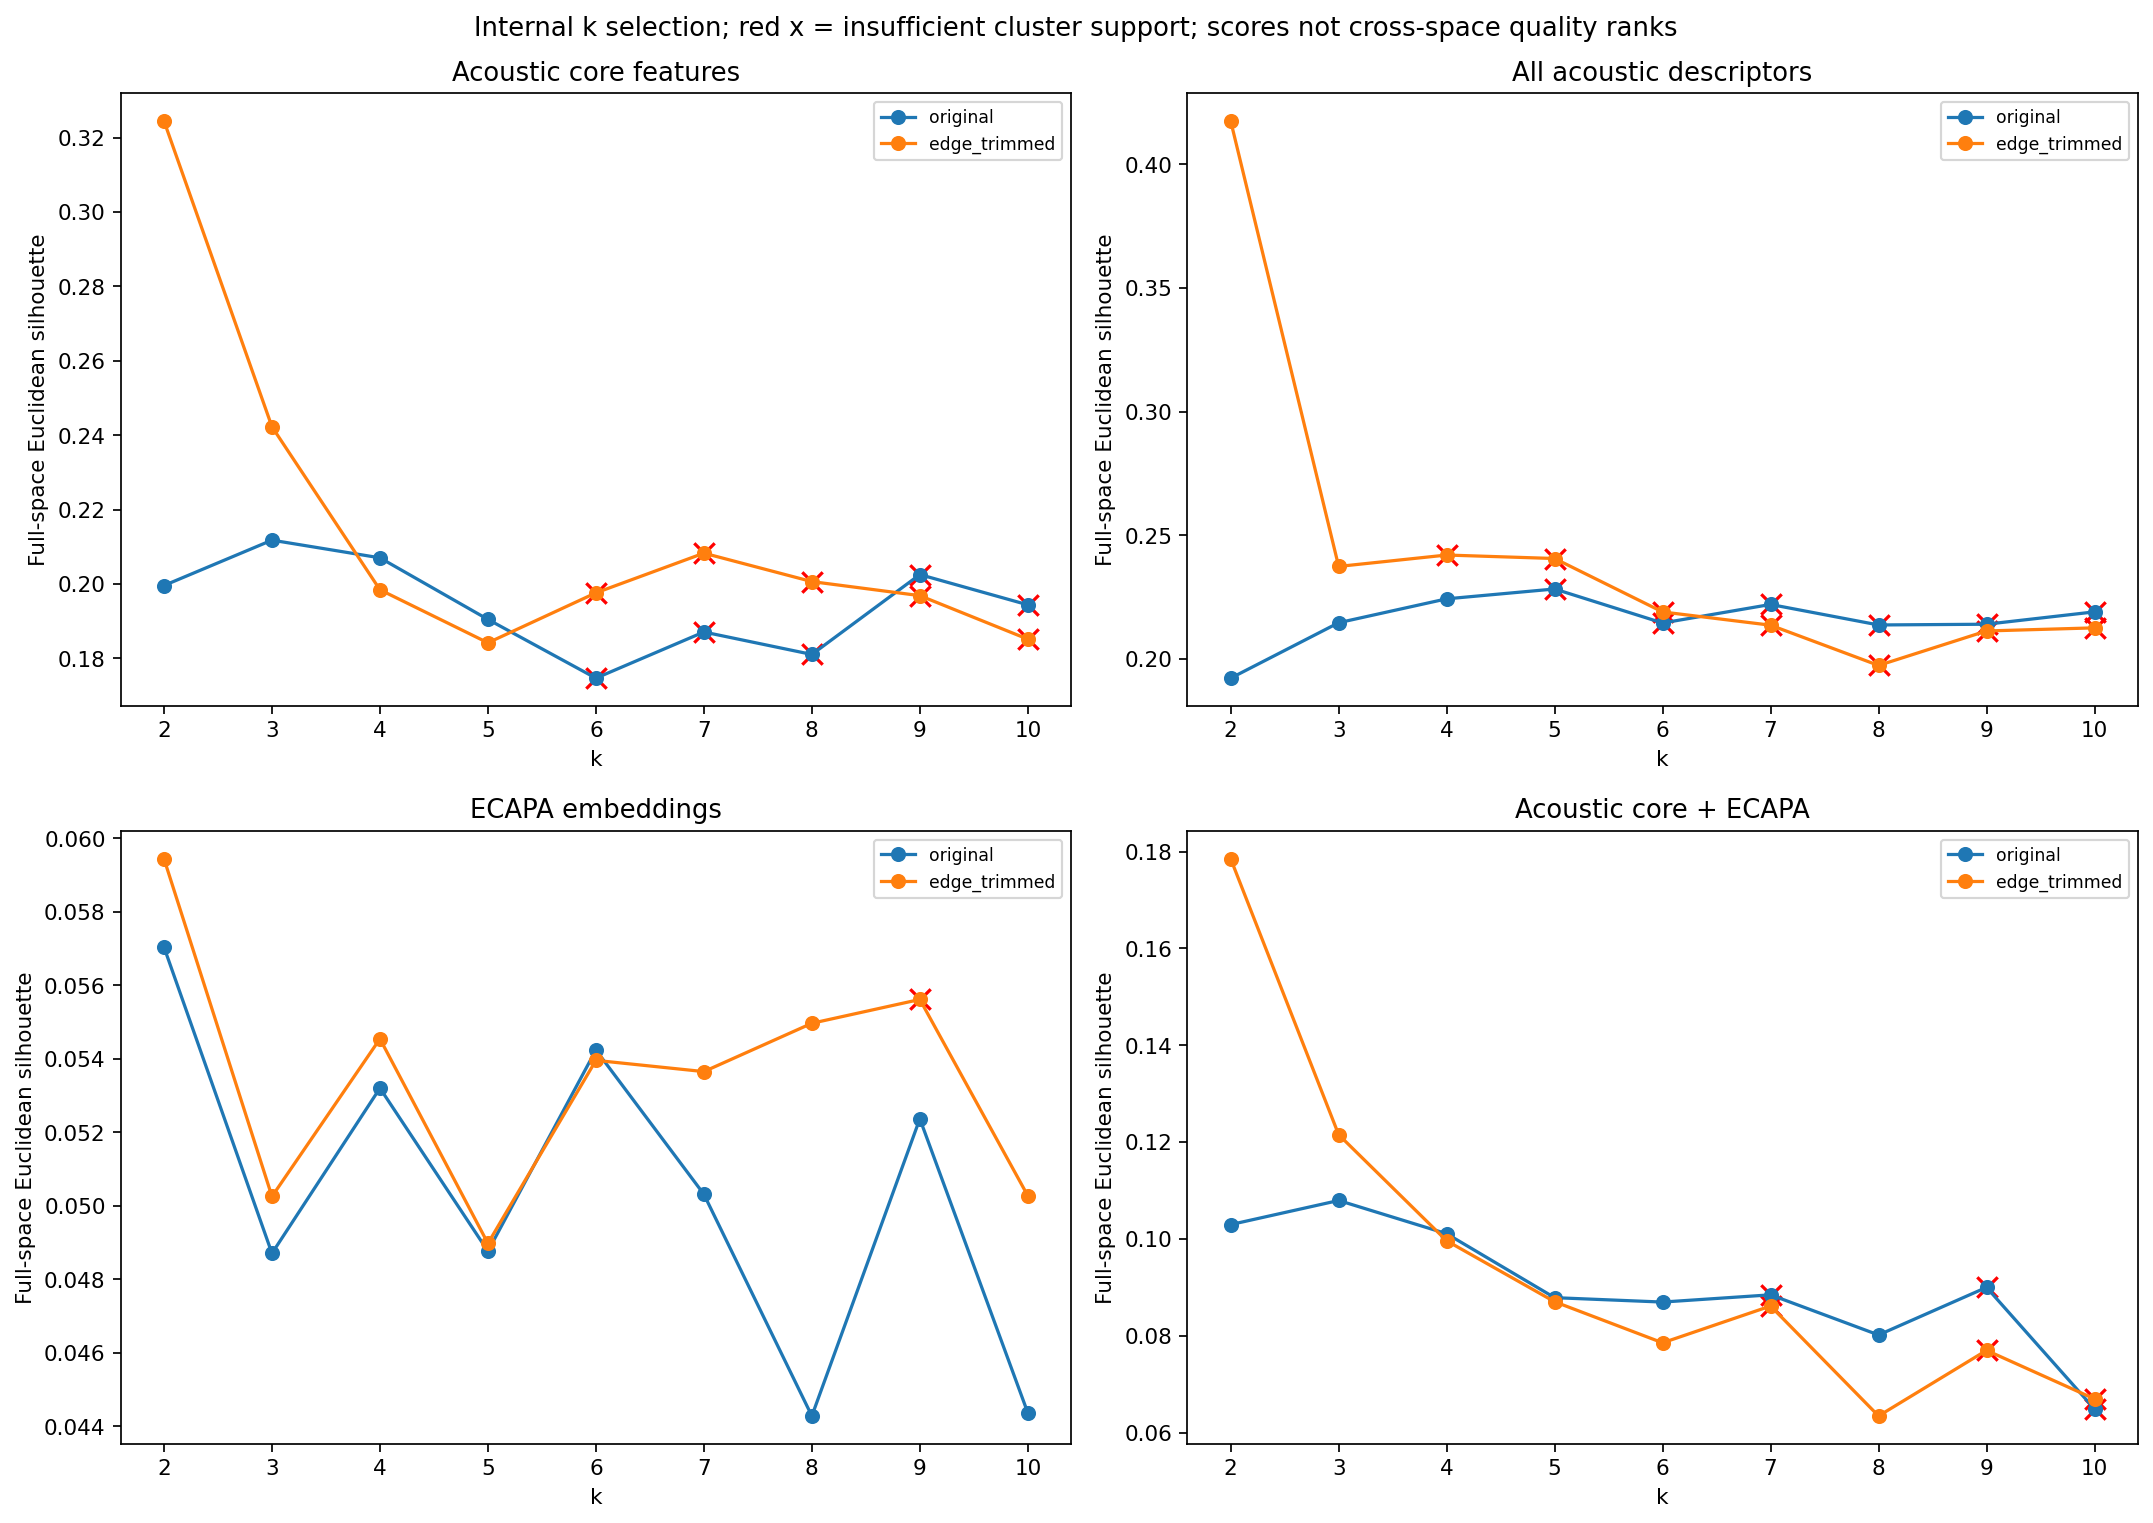

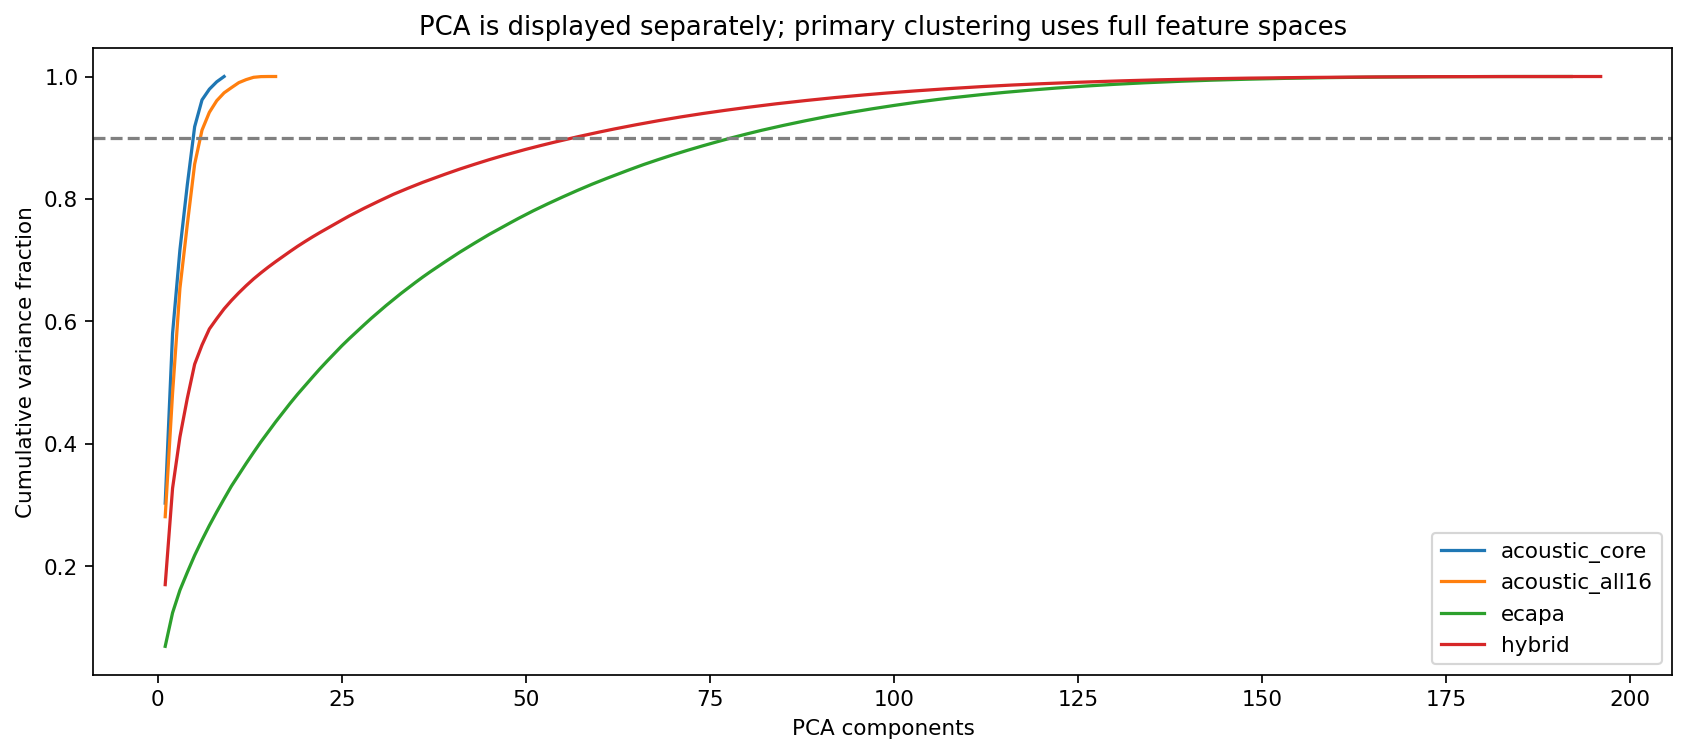

,view,space,kind,dimensions,ari
0,original,acoustic_core,PCA90_same_k,5,0.984948
1,original,acoustic_core,no_cap_same_k,9,1.000000
2,original,acoustic_all16,PCA90_same_k,6,0.972314
3,original,acoustic_all16,no_cap_same_k,16,0.986717
4,original,ecapa,PCA90_same_k,78,1.000000
5,original,hybrid,PCA90_same_k,57,0.946435
6,original,hybrid,no_cap_same_k,201,1.000000
7,edge_trimmed,acoustic_core,PCA90_same_k,5,0.976909
8,edge_trimmed,acoustic_core,no_cap_same_k,9,0.454613
9,edge_trimmed,acoustic_all16,PCA90_same_k,6,1.000000


In [3]:
display(table('k_selection'))
figure('k_selection_overview')
figure('pca_variance_overview')
display(table('preprocessing_sensitivity'))


## 3. Acoustic core: clusters without ECAPA

Same 196 identities, nine numeric descriptors. Maps show the same coordinates coloured by fitted cluster, then real/synthetic and source family. Silhouette plots retain negative values. The acoustic profile heatmap is post-hoc and in pooled native-feature robust units, with colours capped at +/-3 for display; the full native-unit table is also saved. A profile describes conditions/features, not a cause or human quality category.

The average-linkage dendrogram uses a different clustering method. Its branch labels are aggregated groups, not original clip positions; parentheses count identities. Do not read branch heights as an identity-verification threshold.

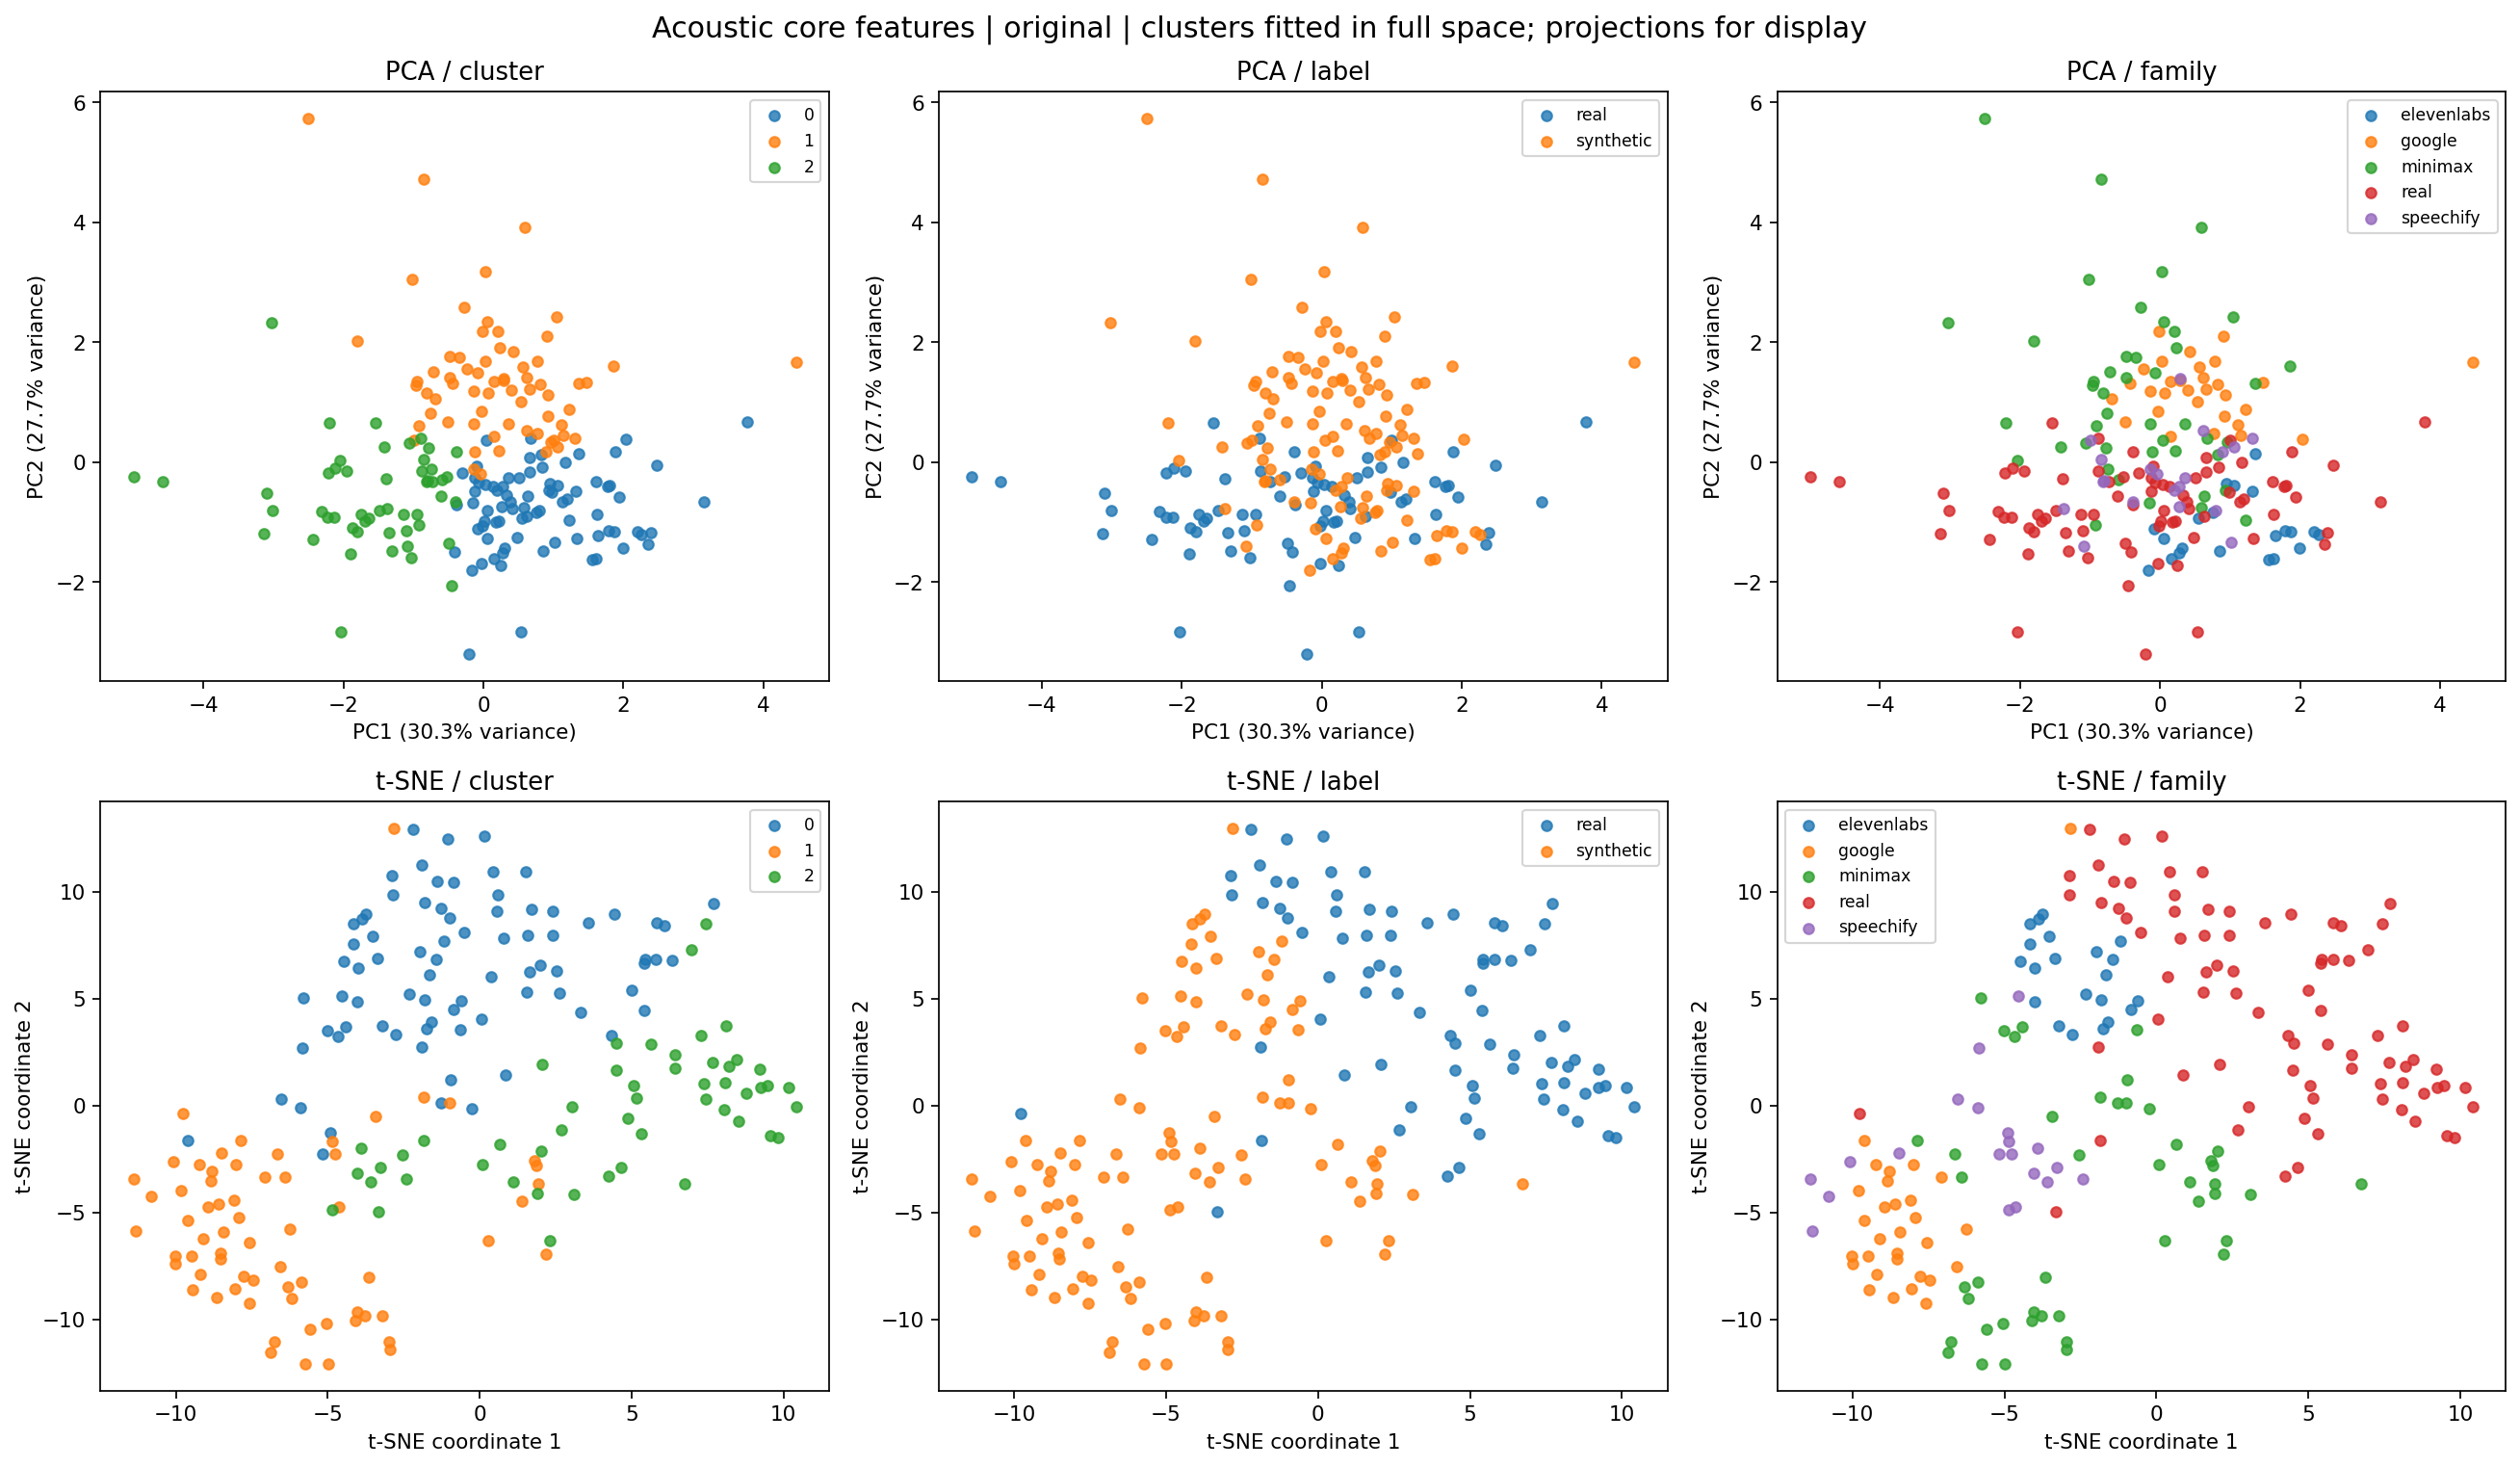

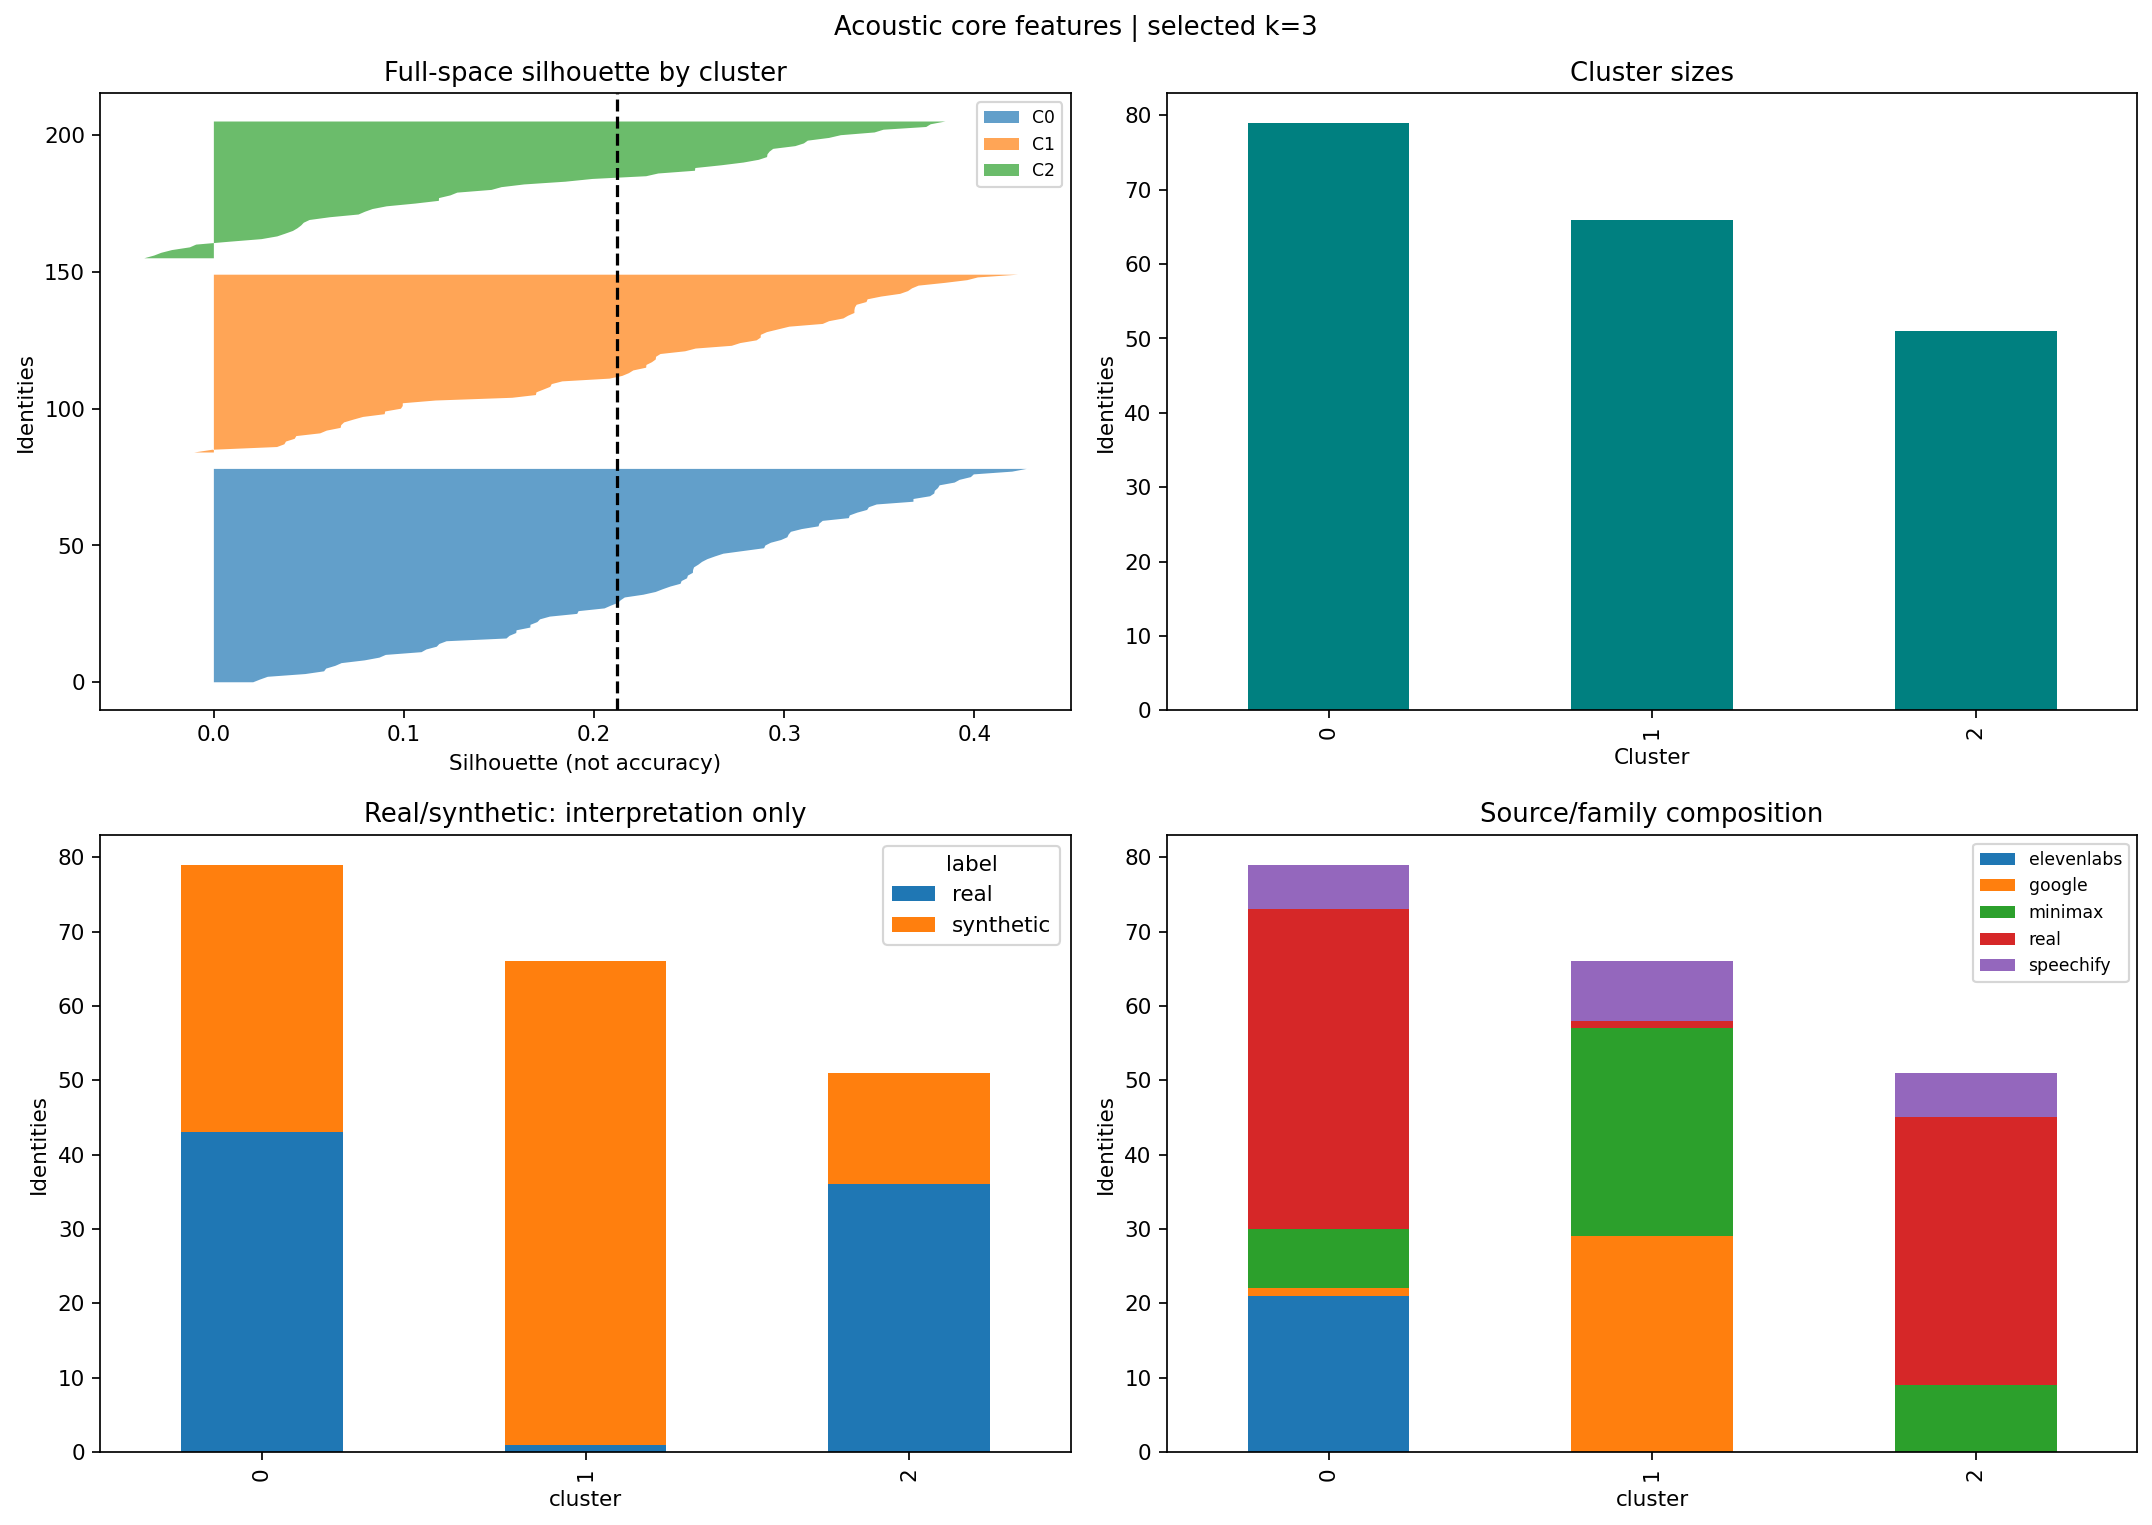

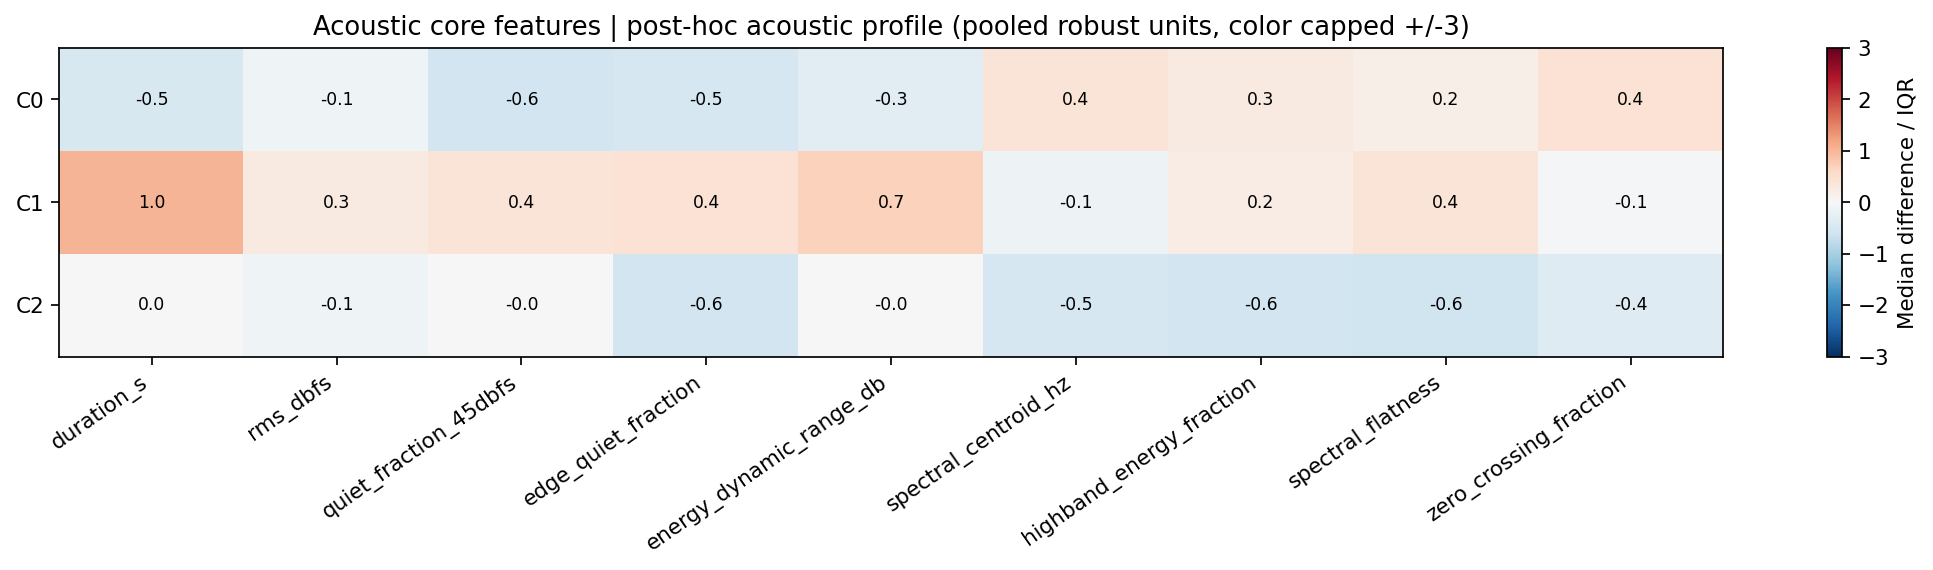

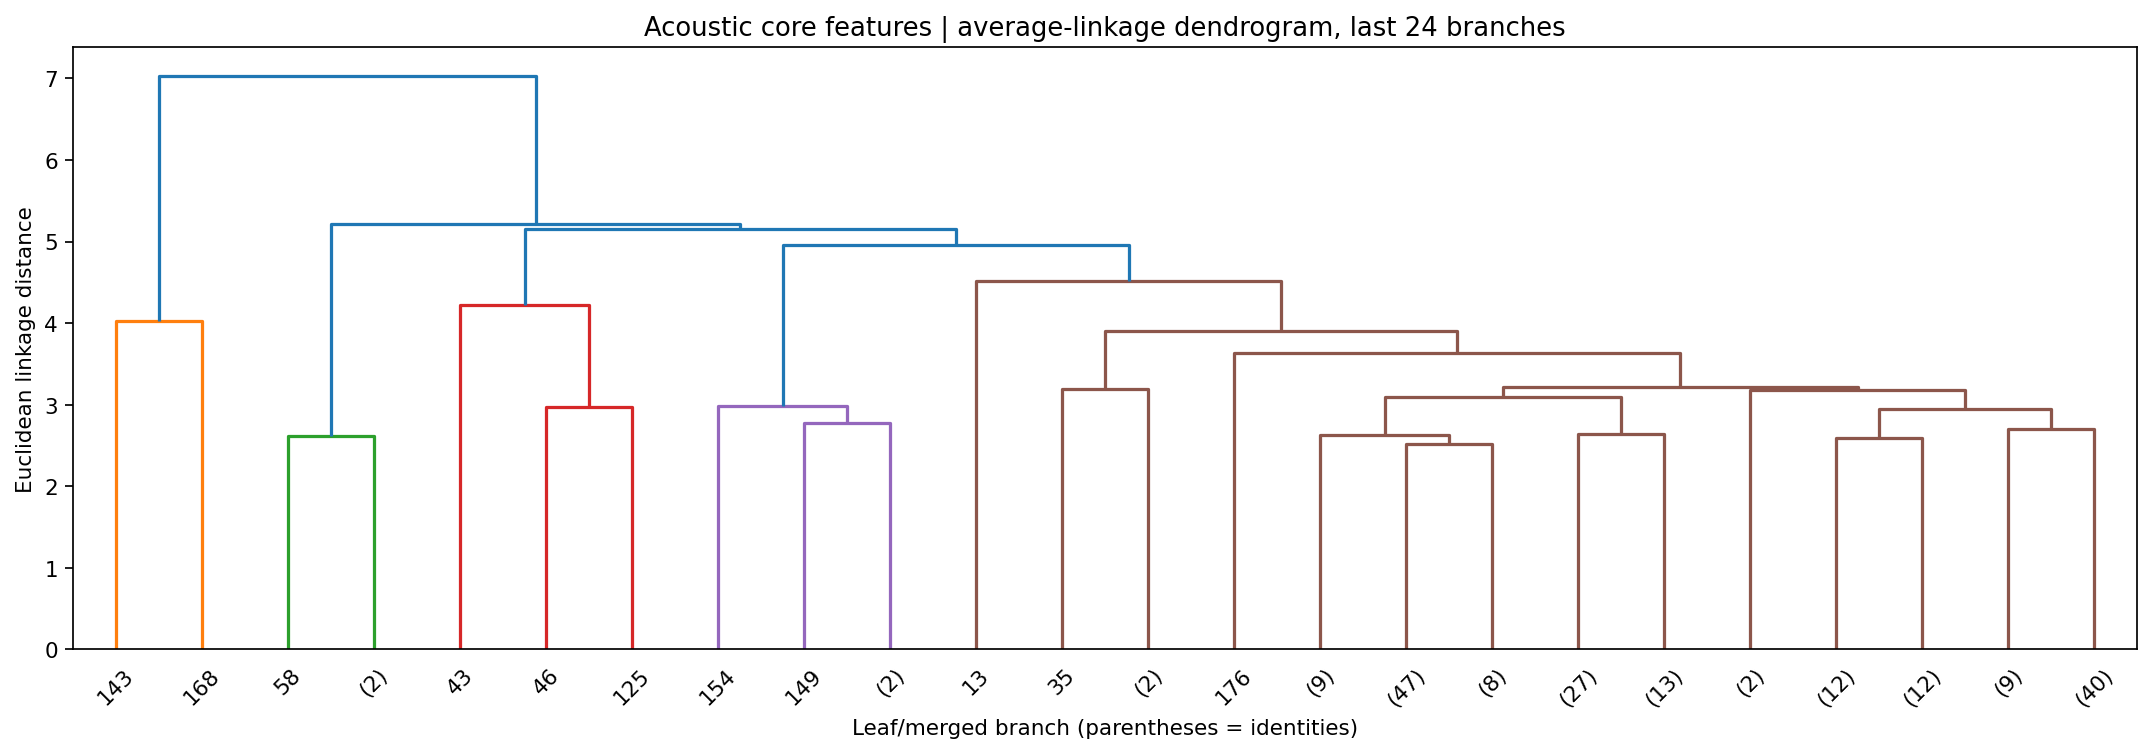

feature,dc_offset,duration_s,edge_quiet_fraction,energy_dynamic_range_db,highband_energy_fraction,leading_quiet_s,near_fullscale_fraction,peak,quiet_fraction_40dbfs,quiet_fraction_45dbfs,quiet_fraction_50dbfs,rms_dbfs,spectral_centroid_hz,spectral_flatness,trailing_quiet_s,zero_crossing_fraction
cluster,,,,,,,,,,,,,,,,
0,-0.000016,4.32000,0.008889,28.946939,0.001447,0.00,0.0,0.647064,0.148472,0.106667,0.078511,-21.448633,501.525692,0.003471,0.02,0.140739
1,-0.000048,4.87075,0.107528,49.429828,0.001371,0.19,0.0,0.760544,0.209288,0.185774,0.170113,-19.240909,429.906061,0.004341,0.28,0.124676
2,-0.000007,4.50000,0.000000,35.721134,0.000209,0.00,0.0,0.610779,0.202633,0.153846,0.128889,-21.440297,380.486019,0.000591,0.00,0.113720


In [4]:
for name in ['acoustic_core_original_maps','acoustic_core_cluster_diagnostics','acoustic_core_acoustic_cluster_profiles','acoustic_core_hierarchy']:
    figure(name)
display(table('cluster_native_feature_profiles').query("view == 'original' and space == 'acoustic_core'").pivot(index='cluster',columns='feature',values='identity_median'))


## 4. ECAPA: voice-representation clusters

KMeans uses Euclidean distances on unit-normalized 192-D identity centroids. This is ordinary KMeans on unit vectors, not a separately implemented spherical KMeans. At point-to-point level, Euclidean and cosine distance have a fixed relationship, but unconstrained cluster means are not unit vectors.

The selected original k=2 partition has low silhouette (~0.057). It nearly tracks real/synthetic origin in this selected sample, despite labels not being used to fit it. Text, codec, channel and the single synthetic prompt remain confounders. That association is neither two verified natural voice categories nor independent deepfake detection performance.

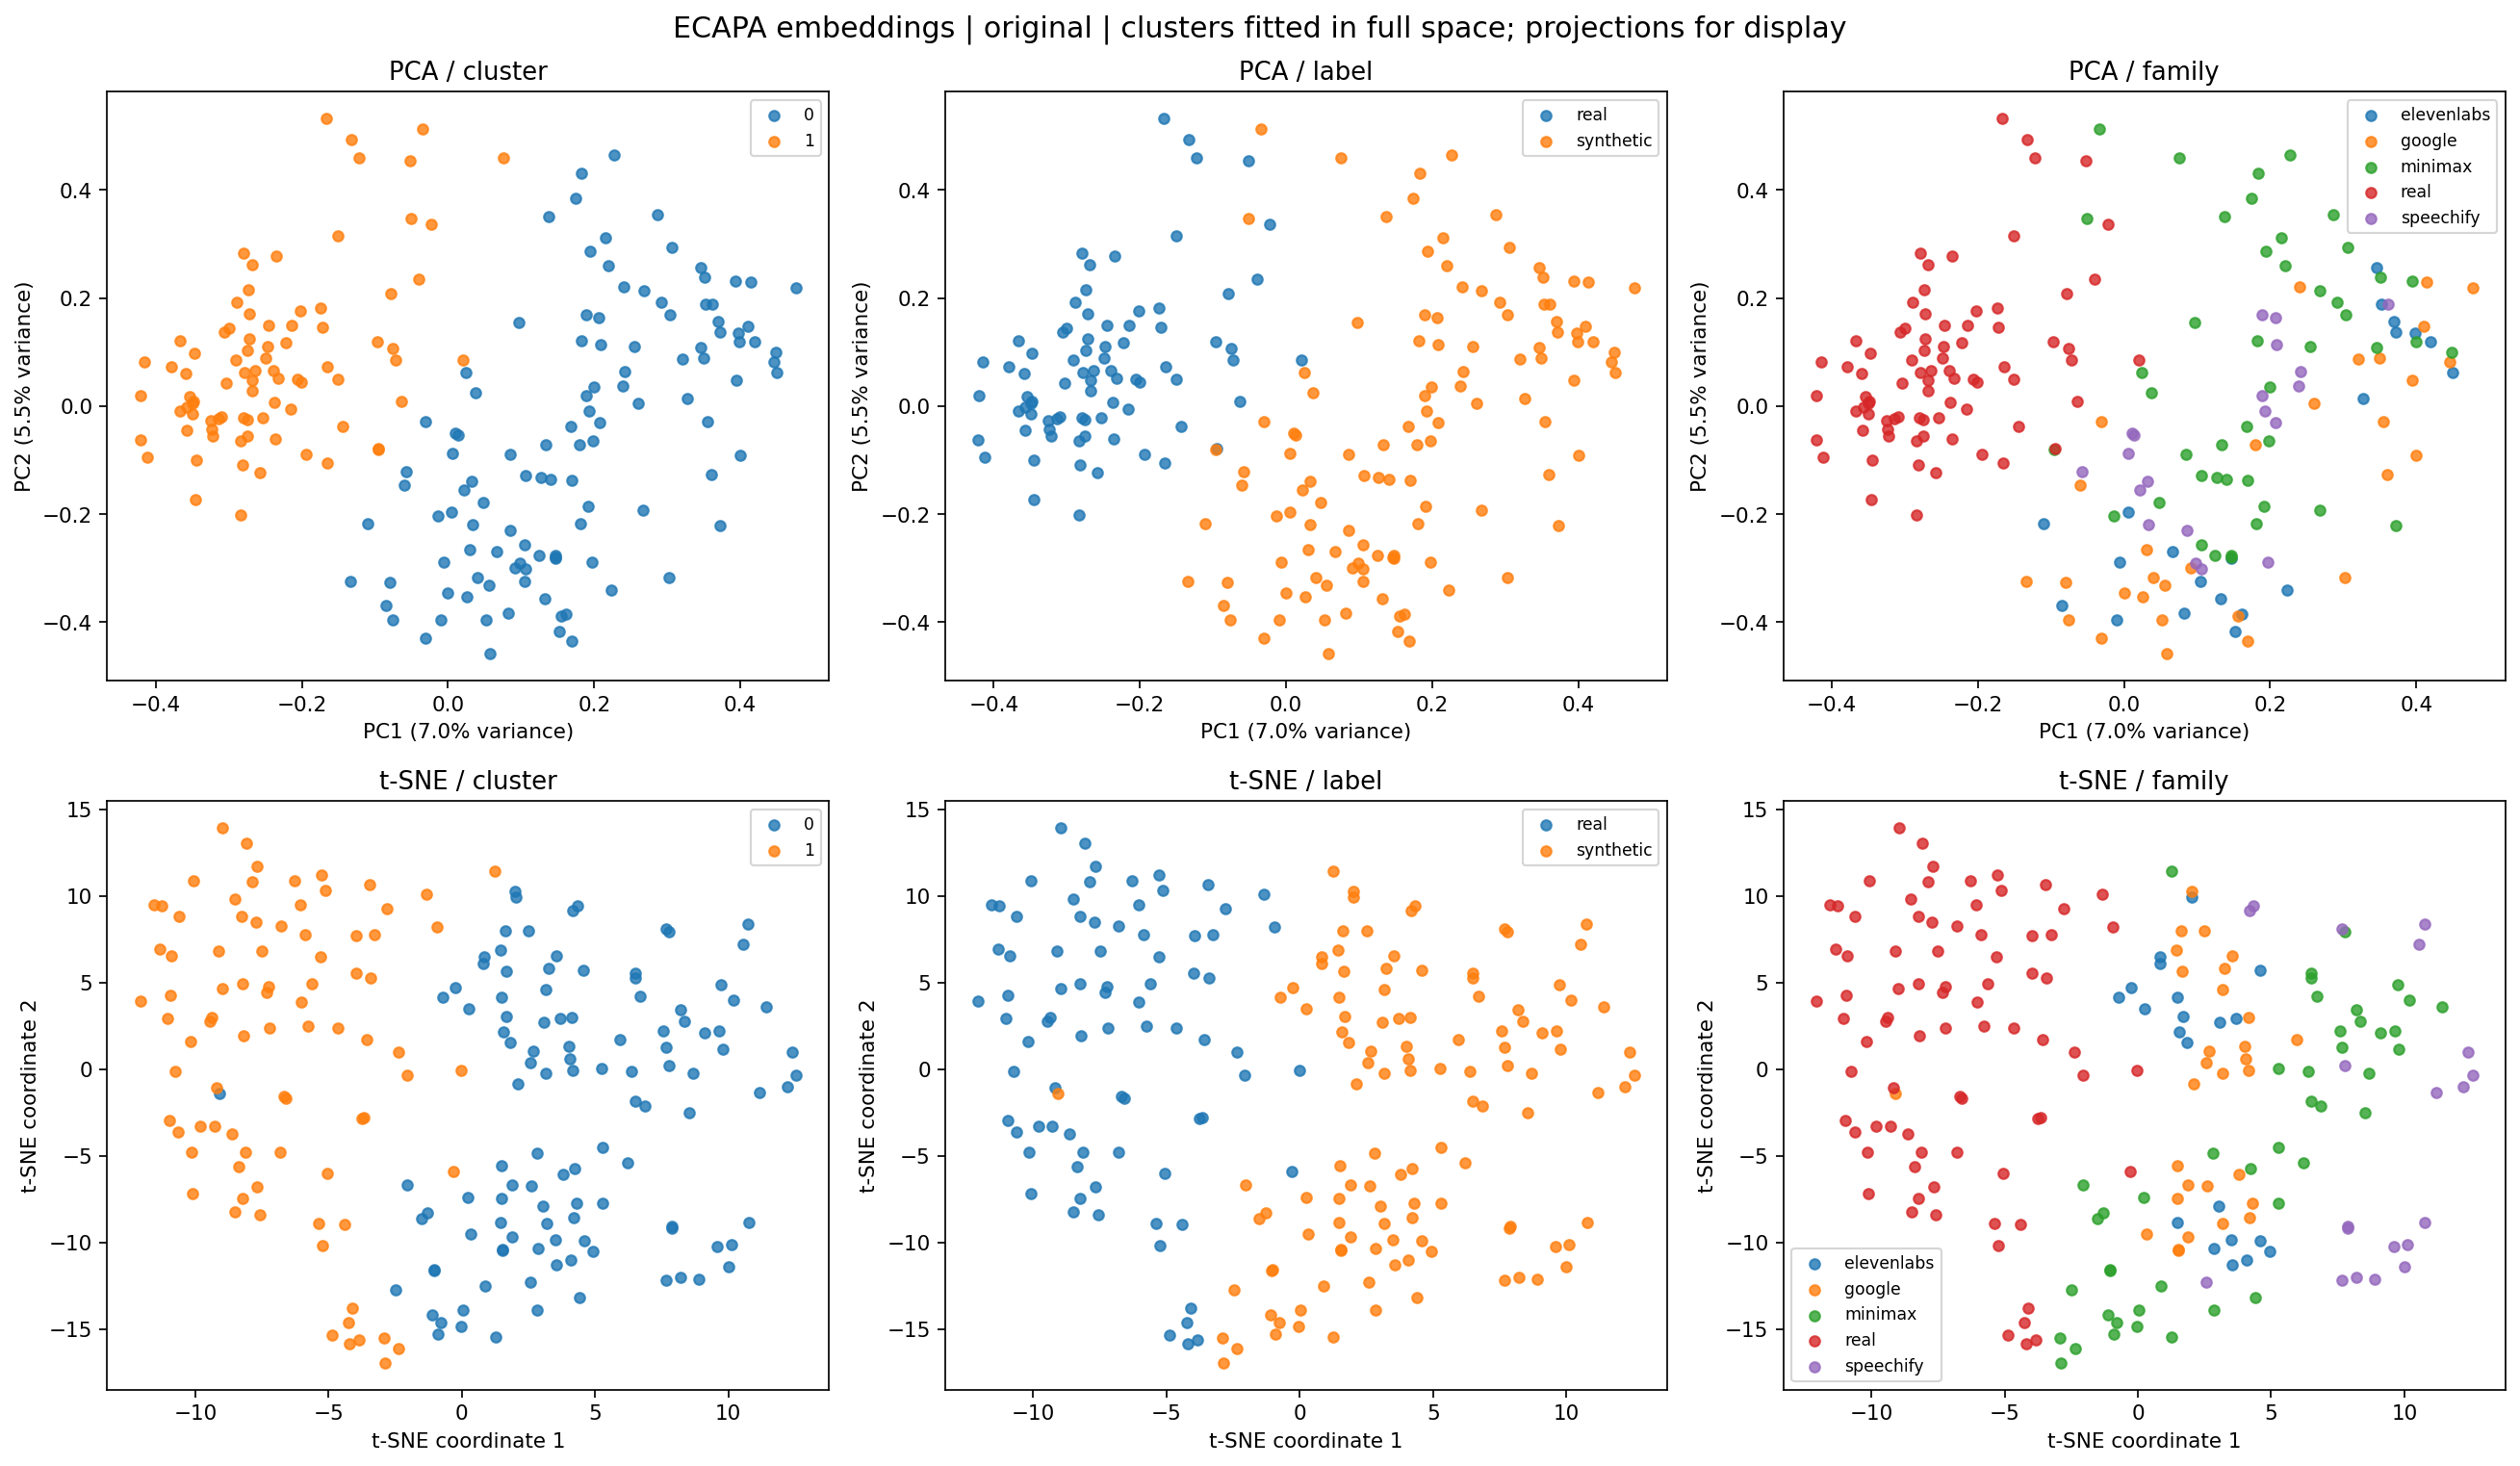

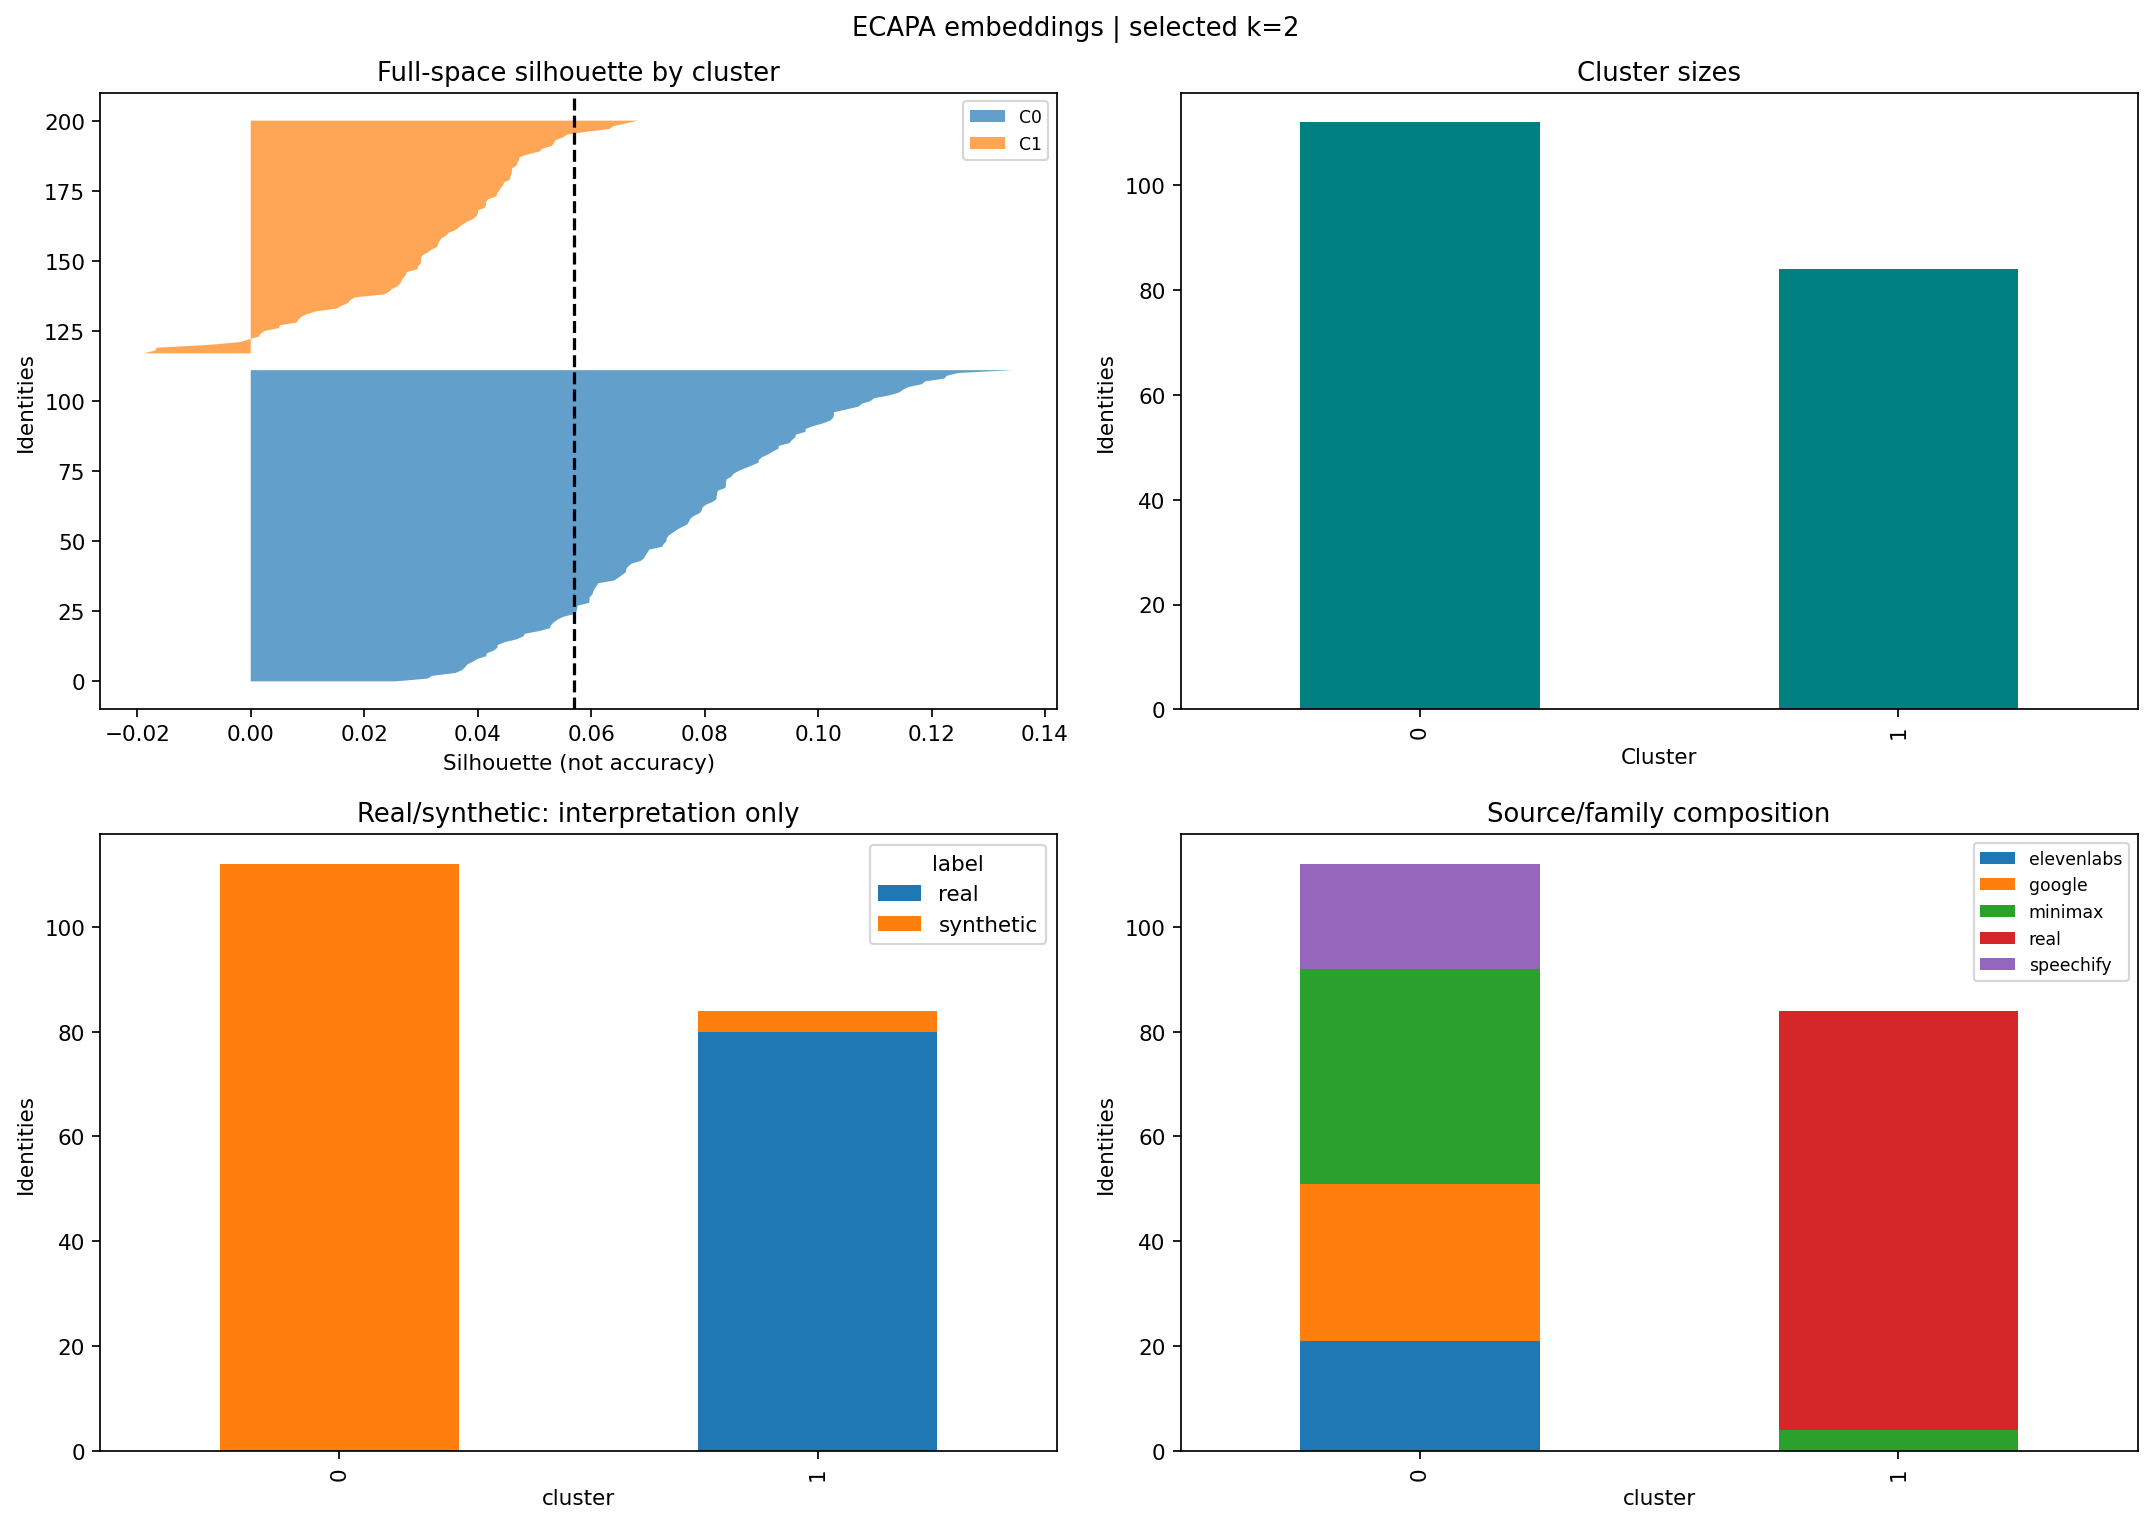

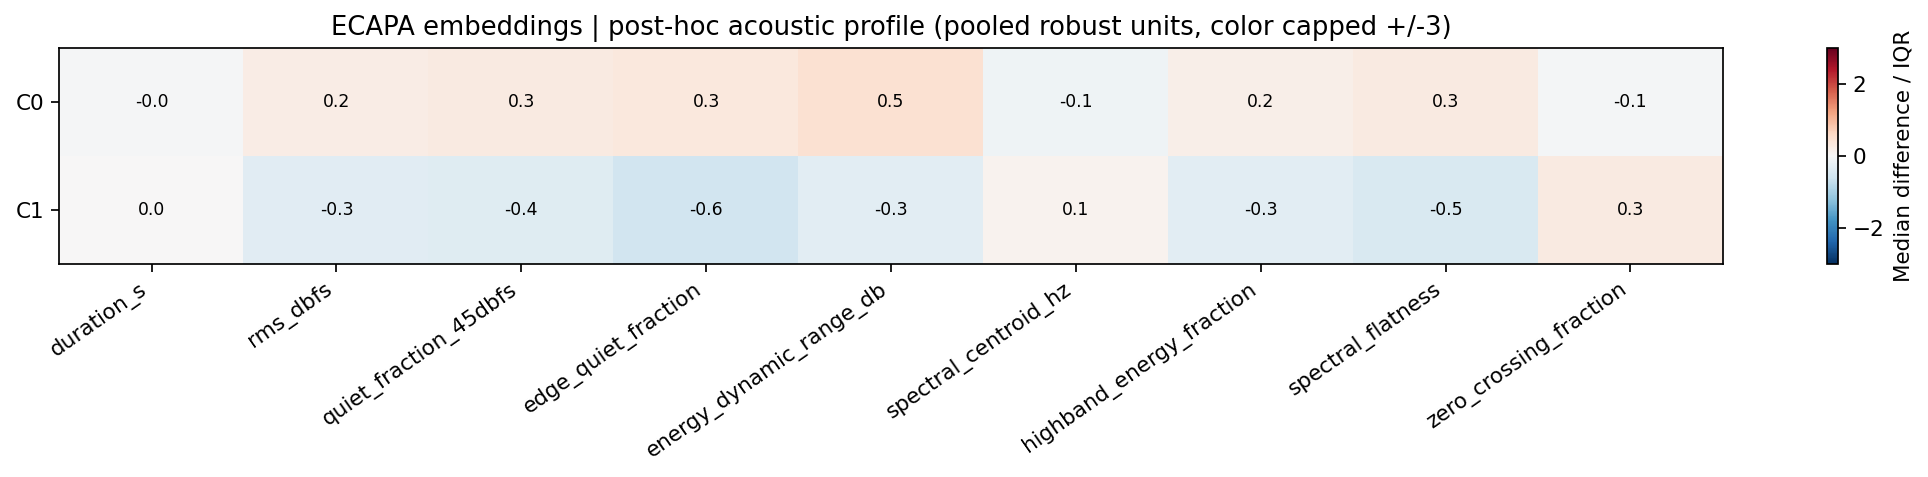

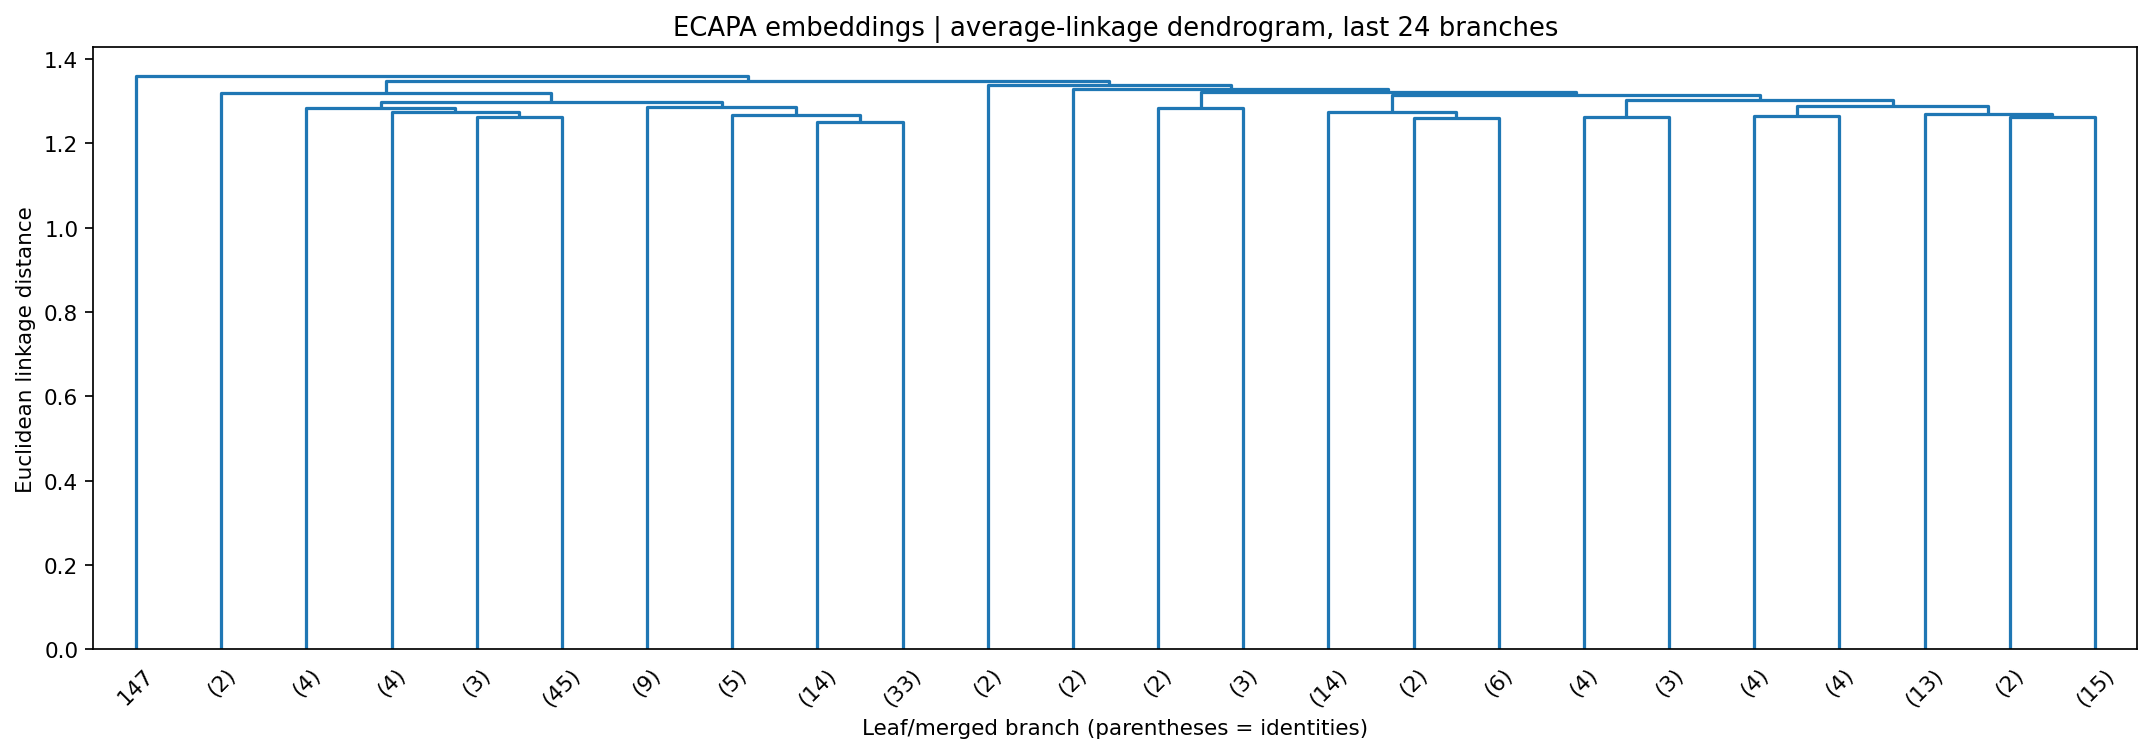

family,elevenlabs,google,minimax,real,speechify
cluster,,,,,
0,21,30,41,0,20
1,0,0,4,80,0


In [5]:
for name in ['ecapa_original_maps','ecapa_cluster_diagnostics','ecapa_acoustic_cluster_profiles','ecapa_hierarchy']:
    figure(name)
display(pd.crosstab(assign.query("view == 'original' and space == 'ecapa'").cluster,assign.query("view == 'original' and space == 'ecapa'").family))


## 5. Hybrid: created acoustic features plus ECAPA

This directly compares clustering with the existing acoustic core plus the learned voice representation. Block scaling was fixed before clustering. Appending 192 unscaled coordinates to nine acoustic values without a defined weighting would make the comparison harder to interpret. A different scientifically justified weight could still produce another partition.

Hybrid clusters are a feature-combination sensitivity, not proof that more features improve quality. Observe the low internal separation and changes across boundaries, algorithms and subsamples.

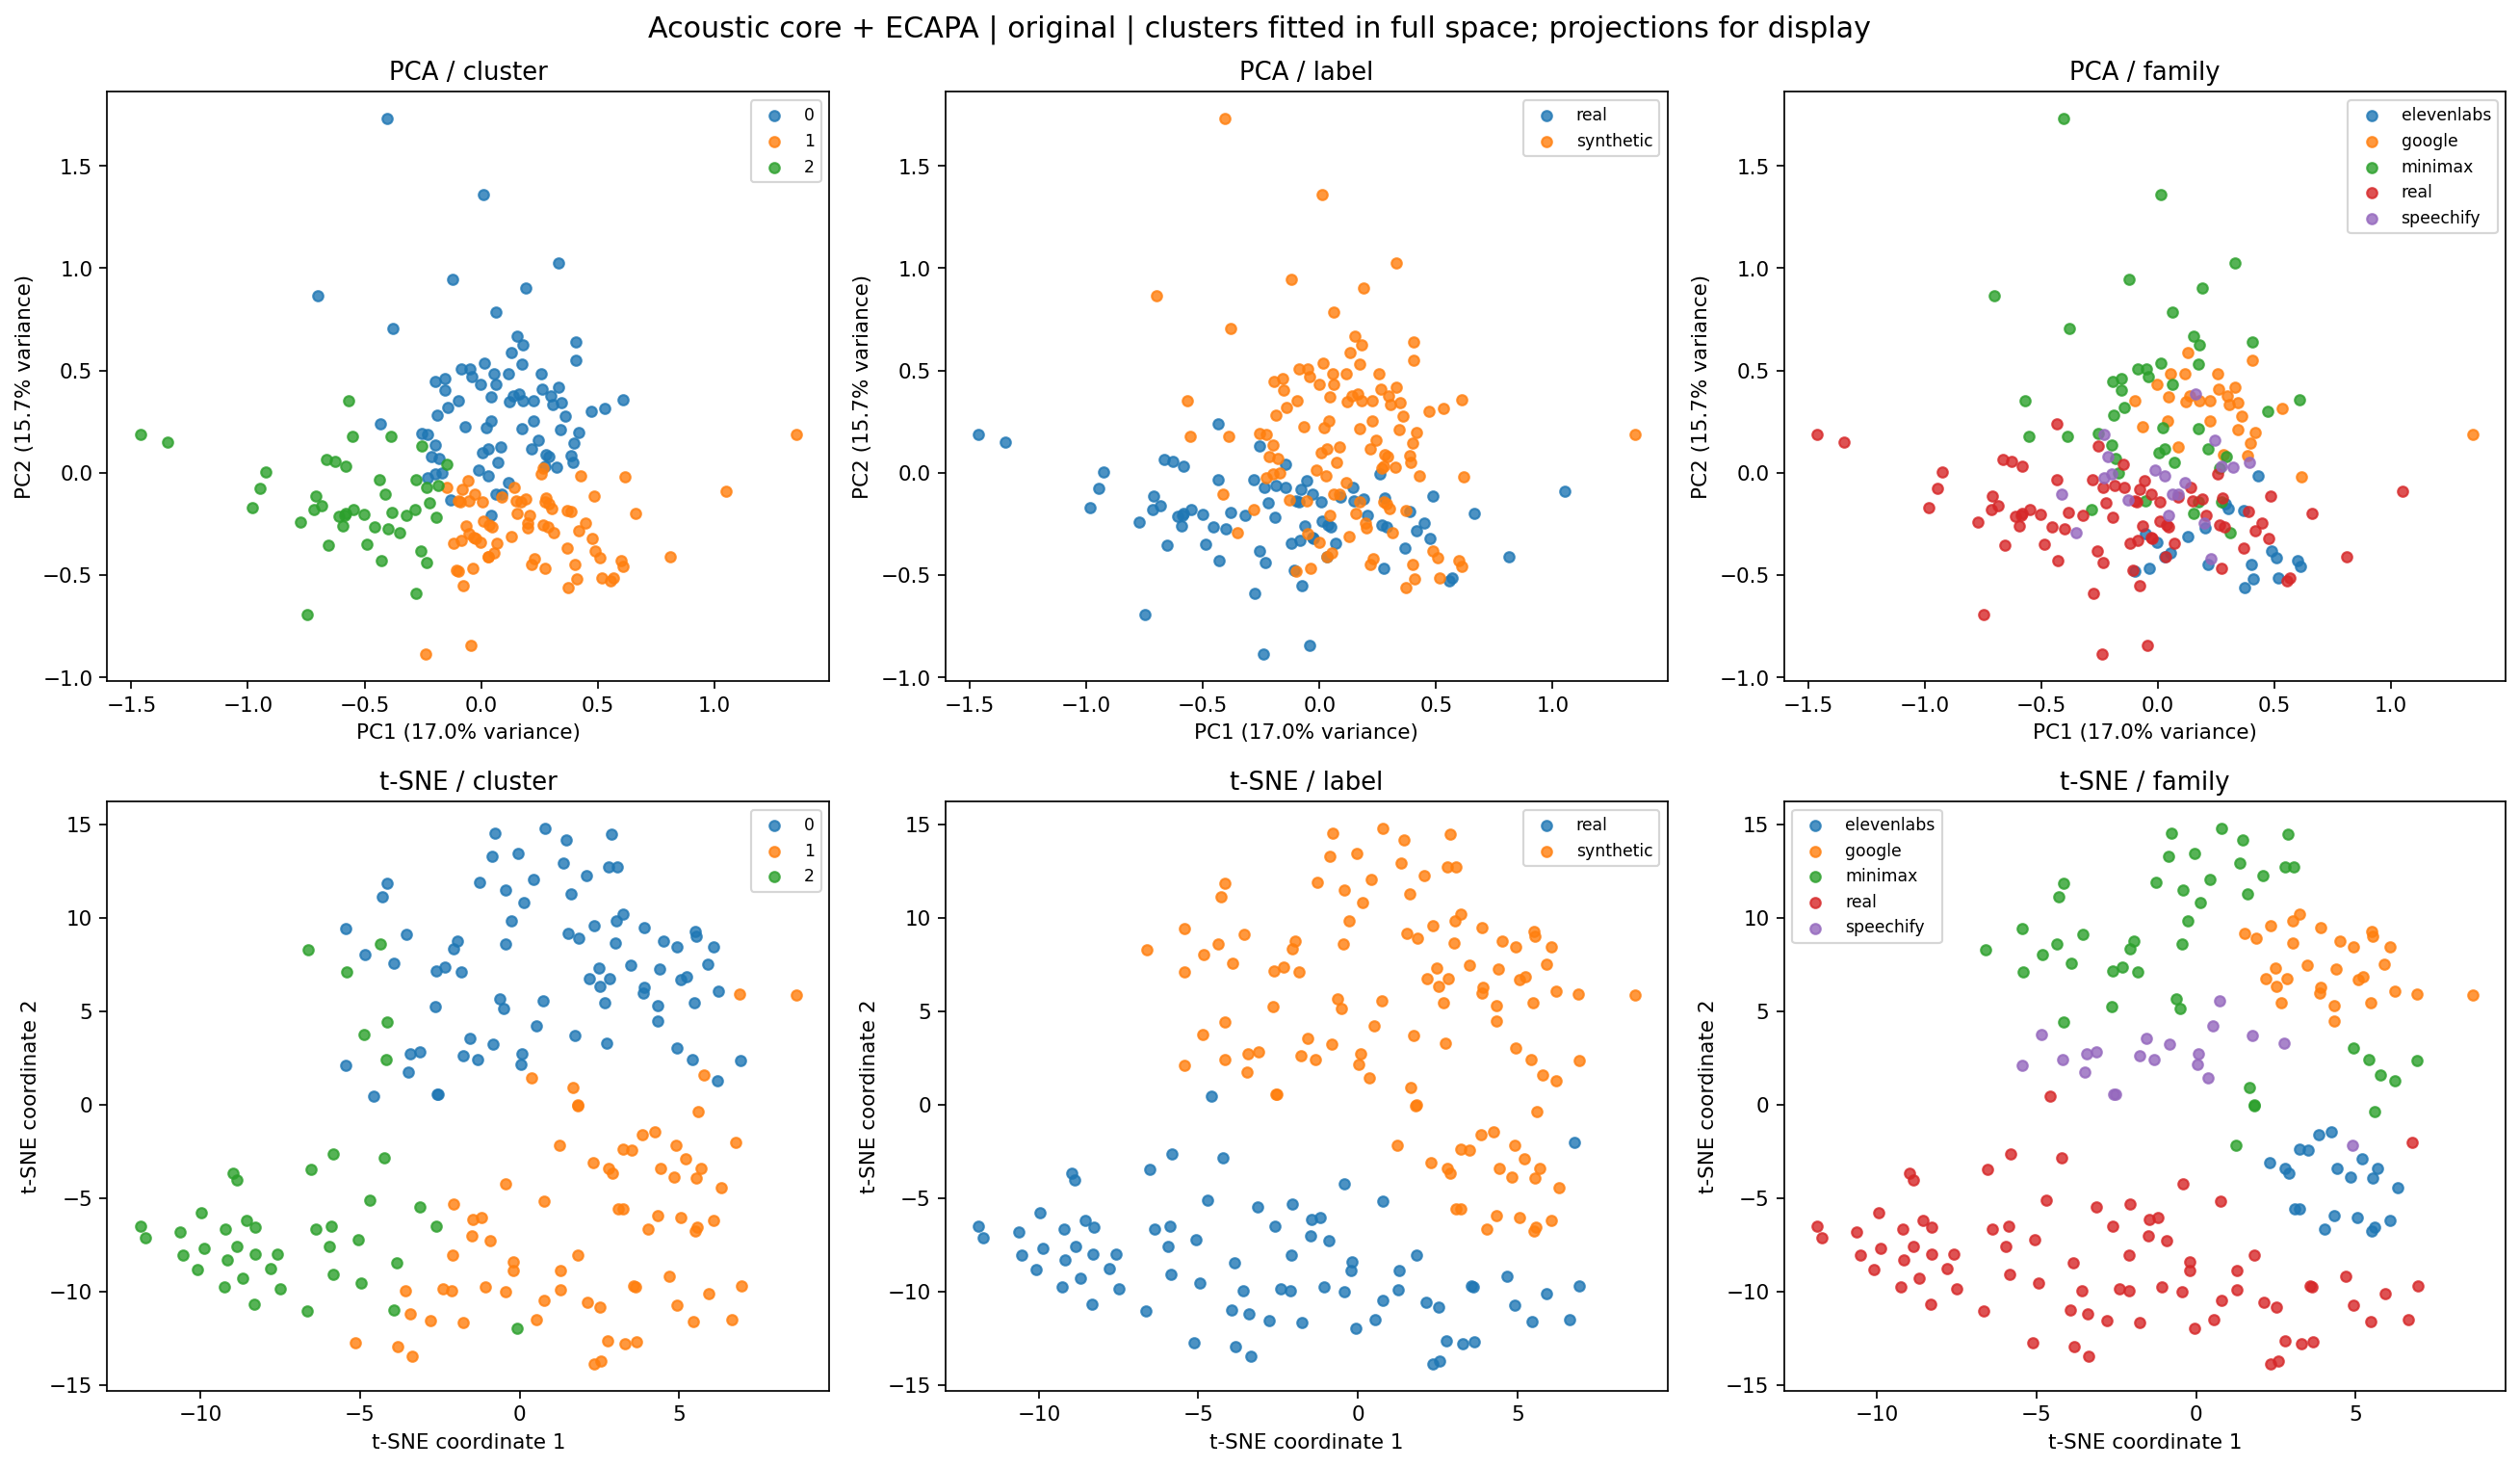

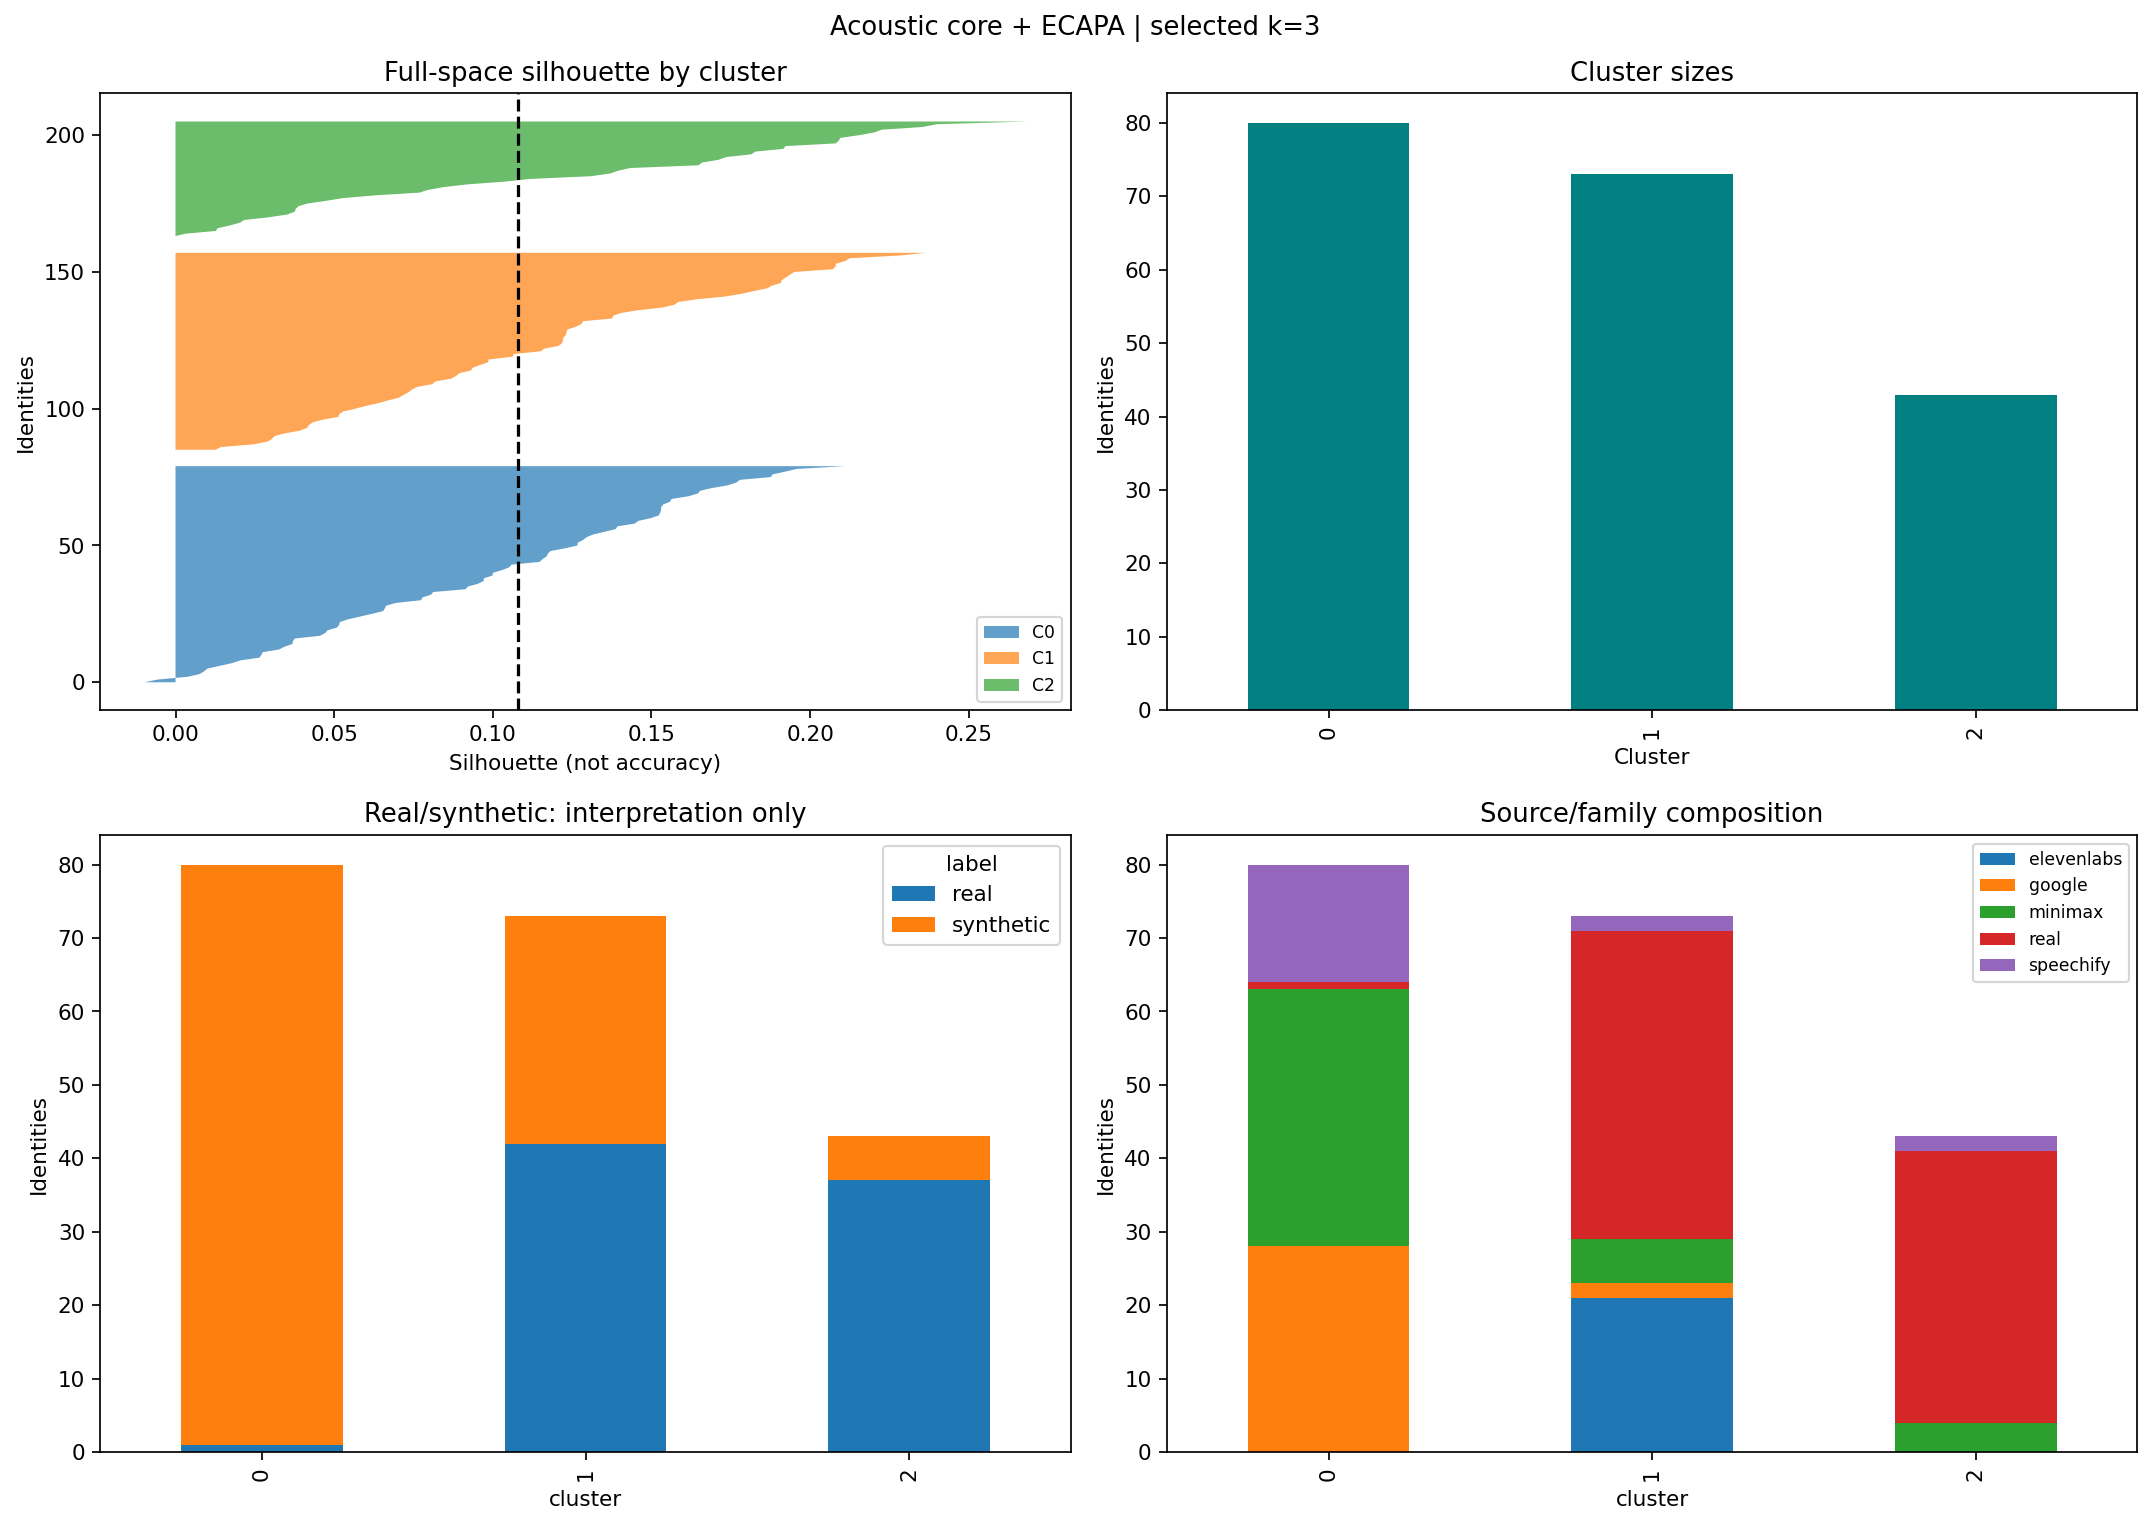

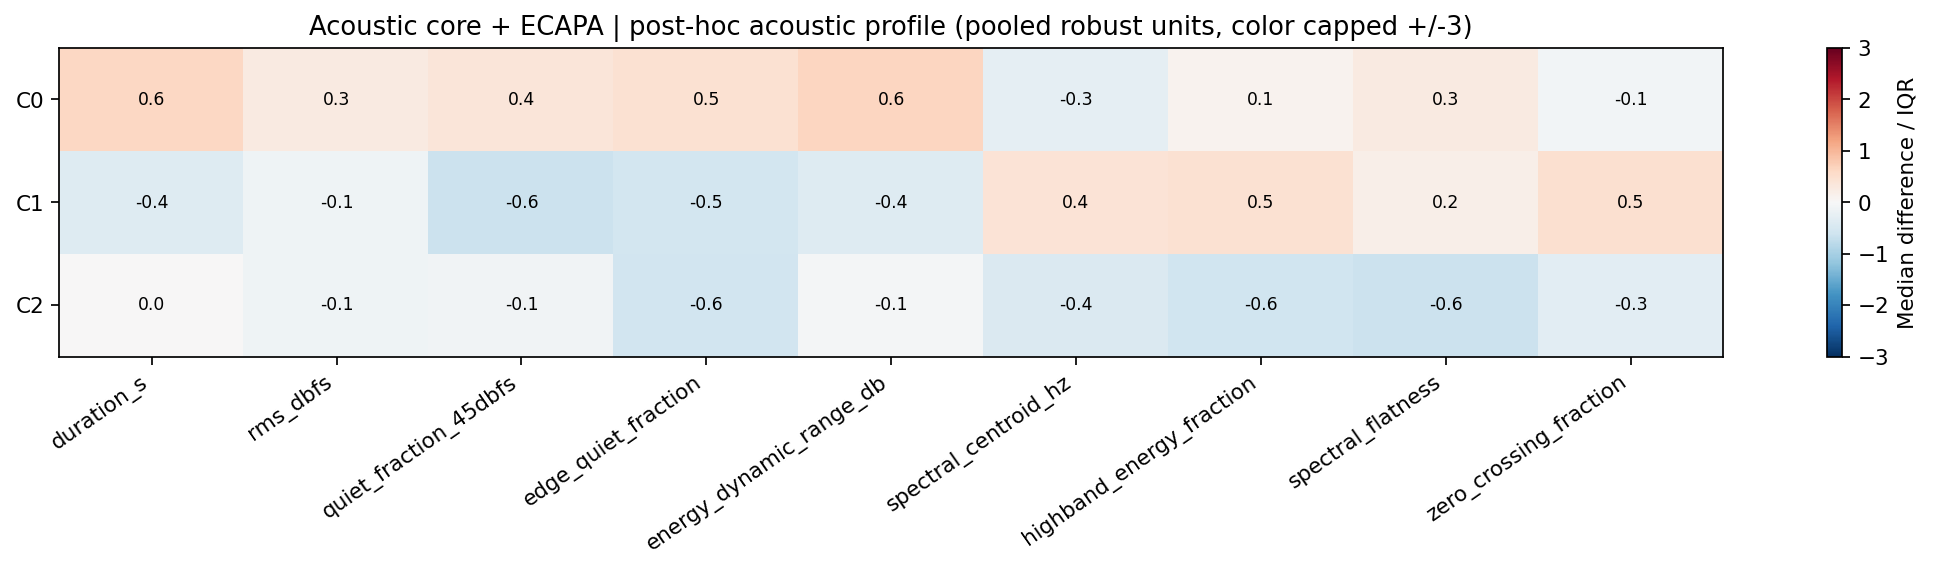

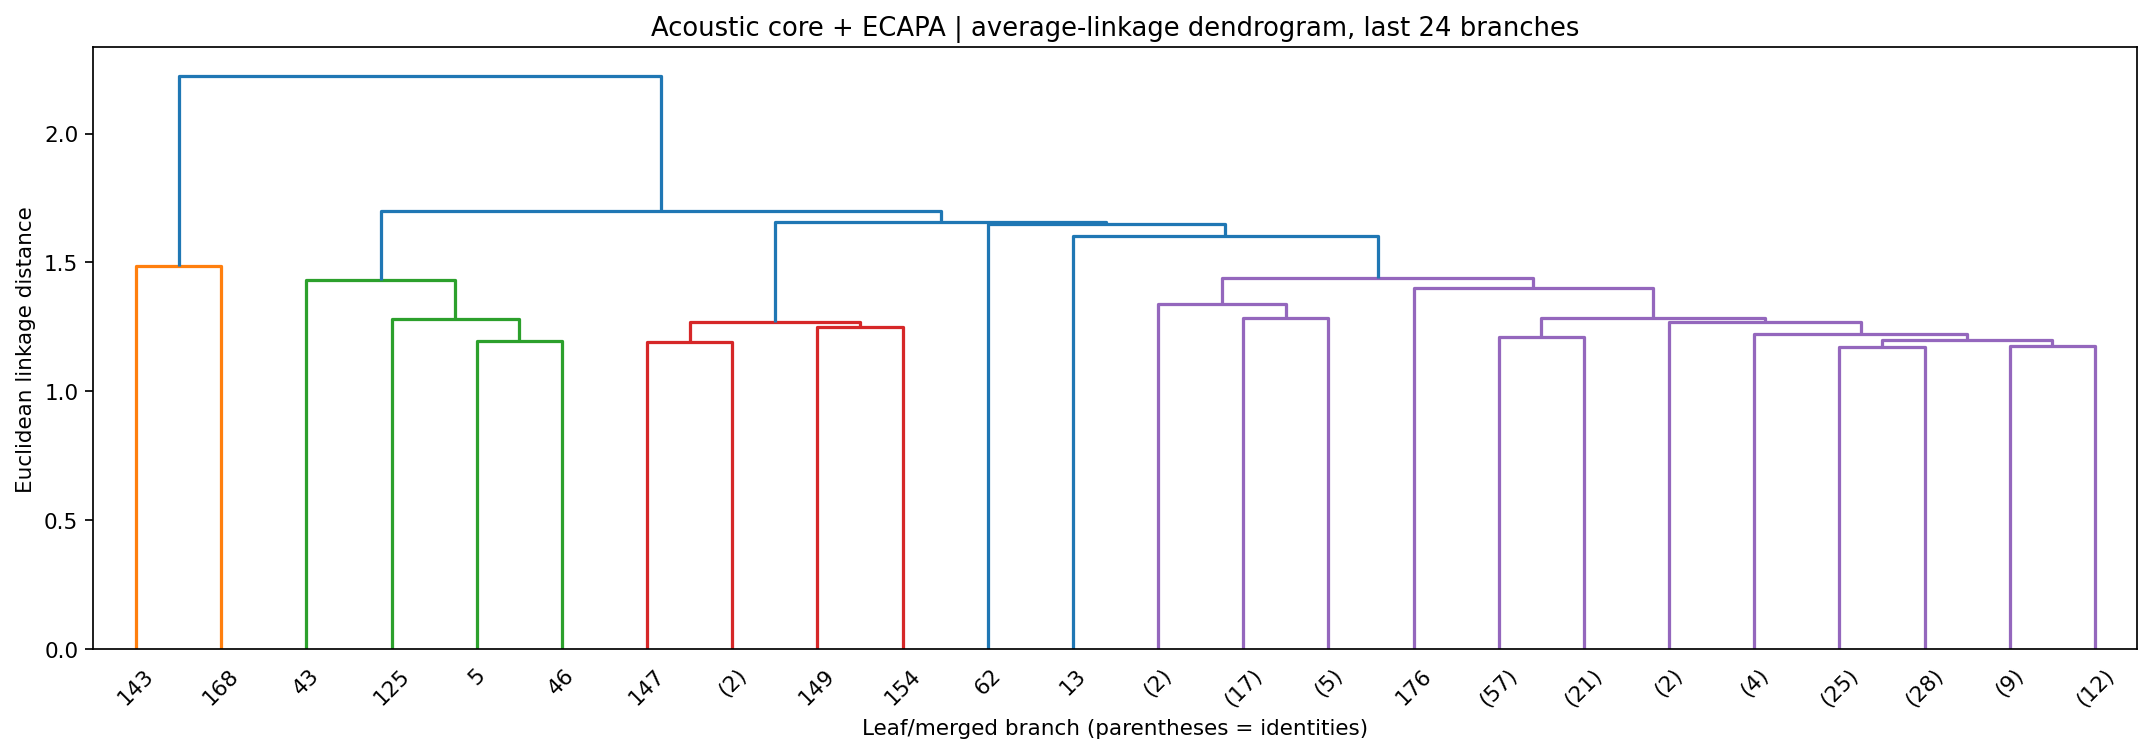

In [6]:
for name in ['hybrid_original_maps','hybrid_cluster_diagnostics','hybrid_acoustic_cluster_profiles','hybrid_hierarchy']:
    figure(name)


## 6. All 16 created descriptors: redundancy sensitivity

Several quiet and edge descriptors describe related aspects of the waveform. Their inclusion changes how much weight those conditions get, even after per-feature scaling. Compare the all-descriptor result with the core result rather than claiming it is superior because its silhouette is larger.

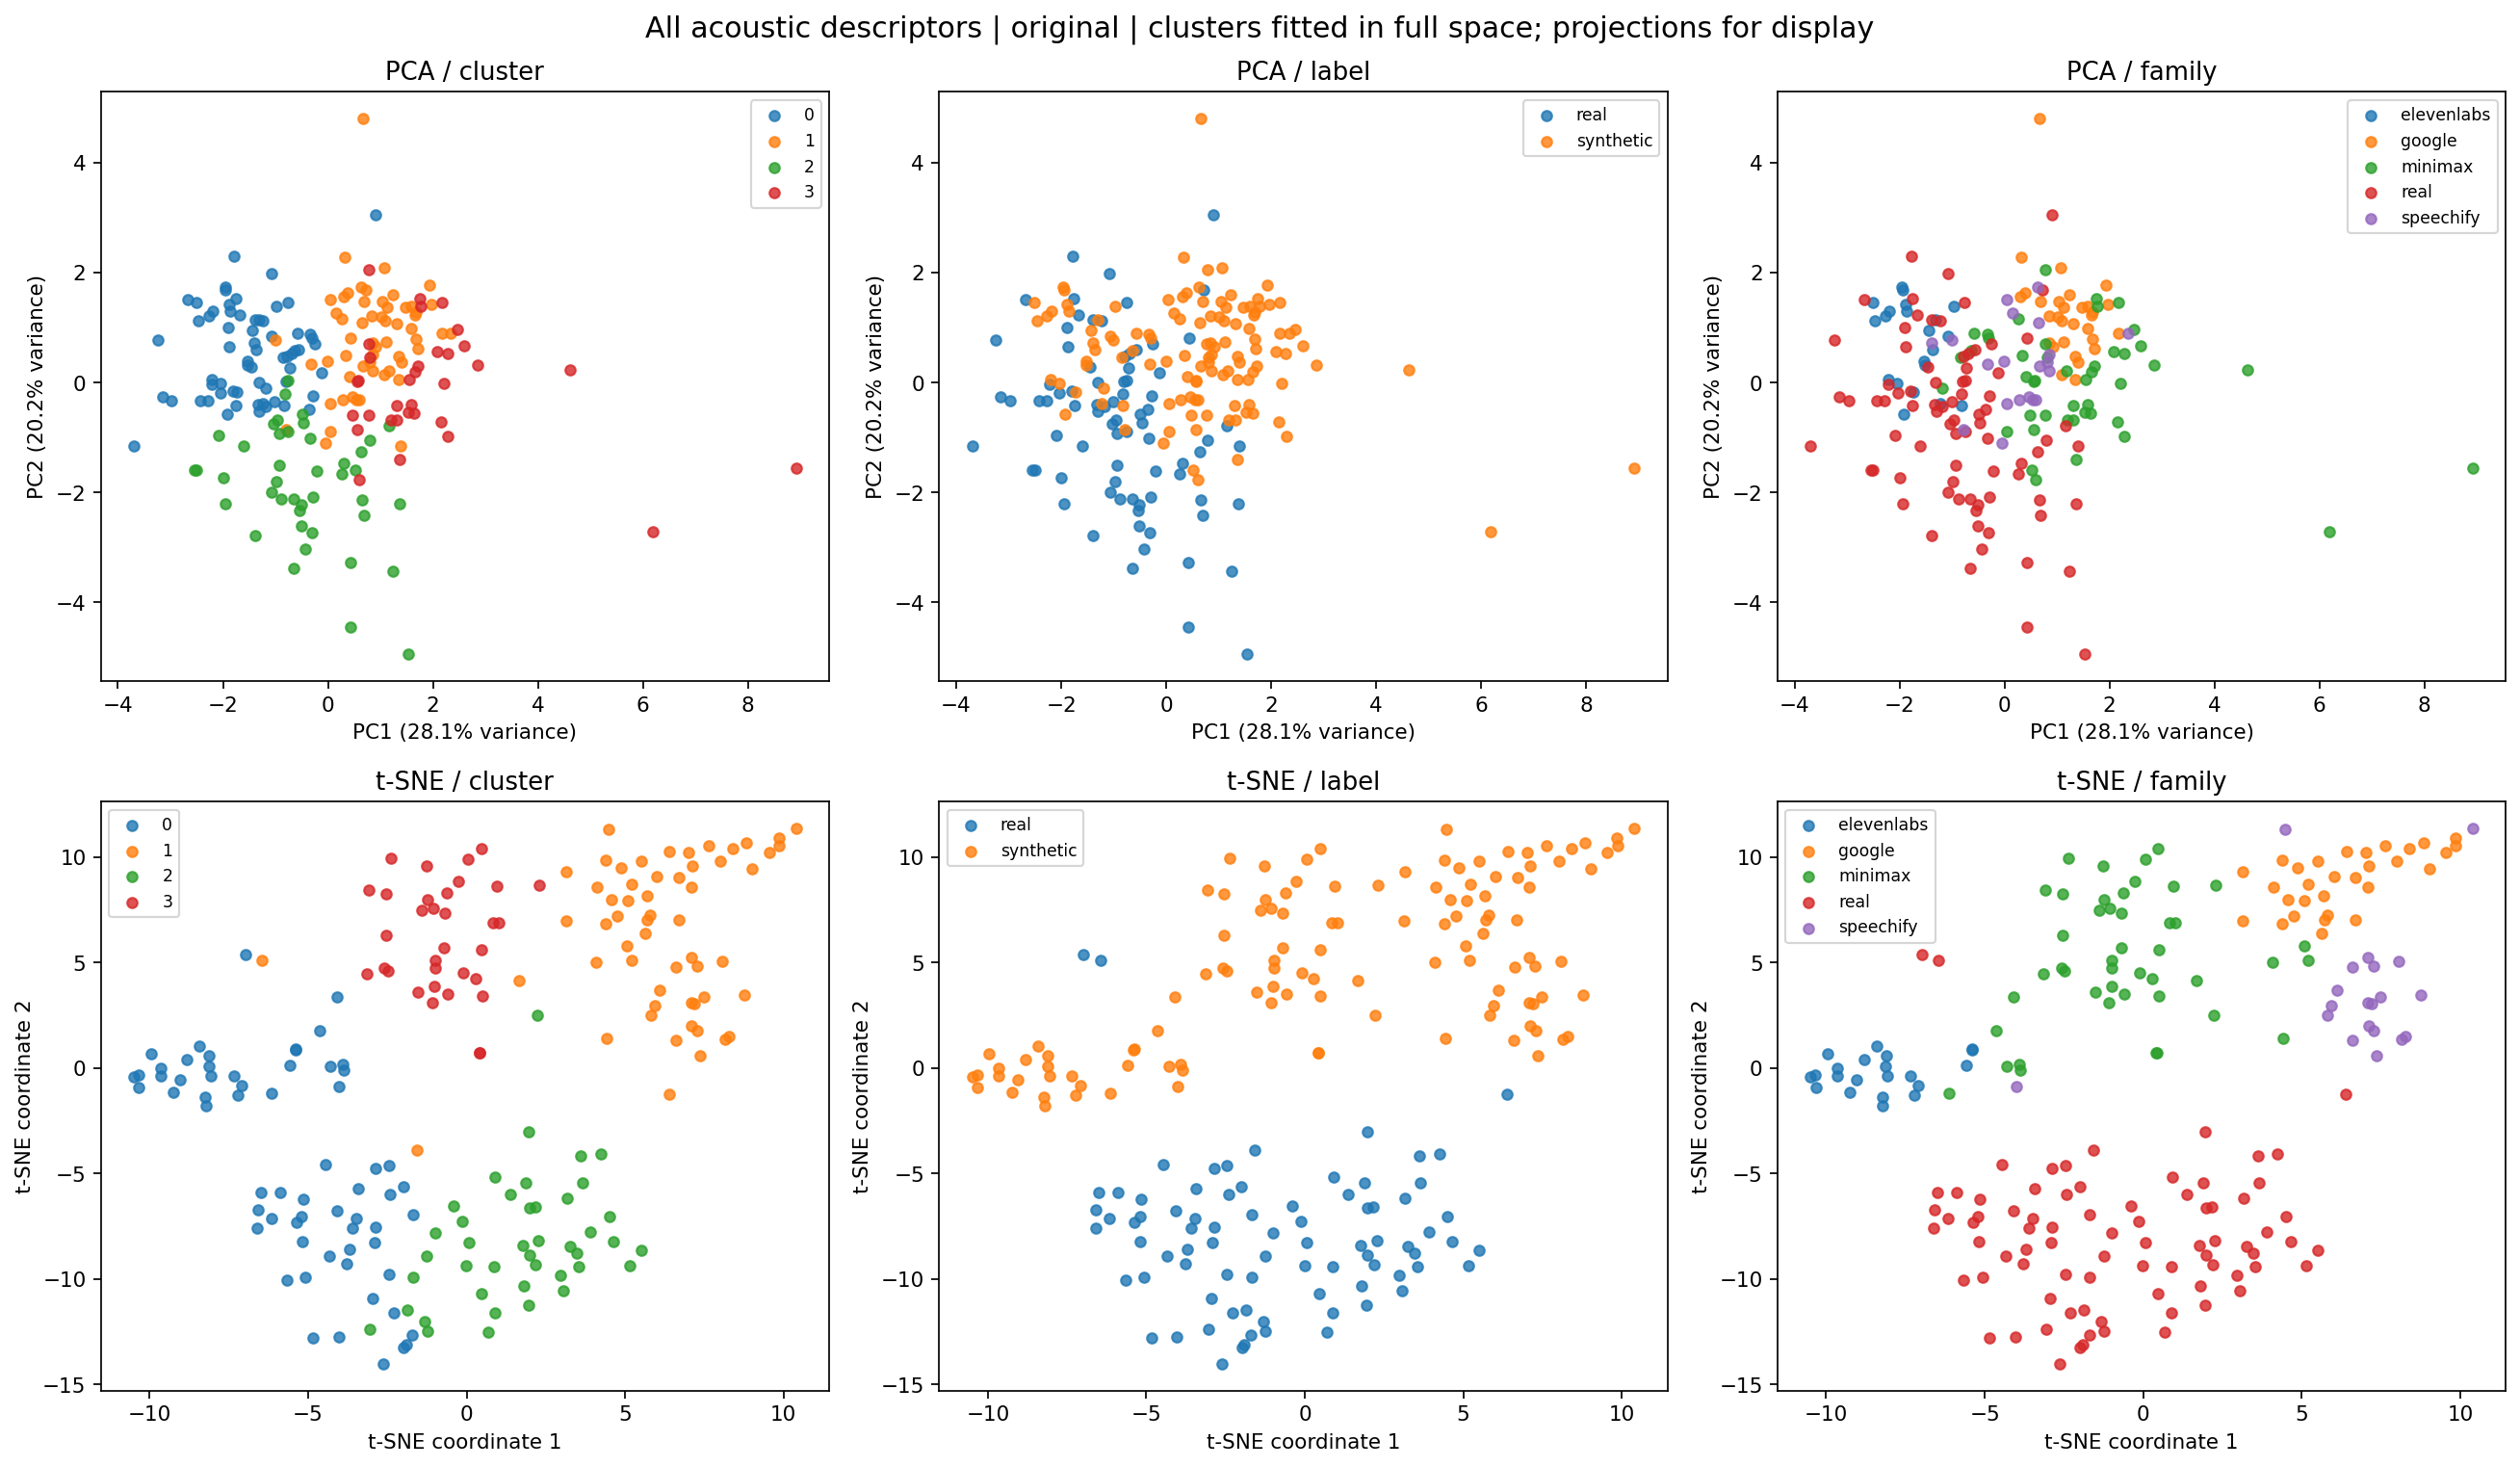

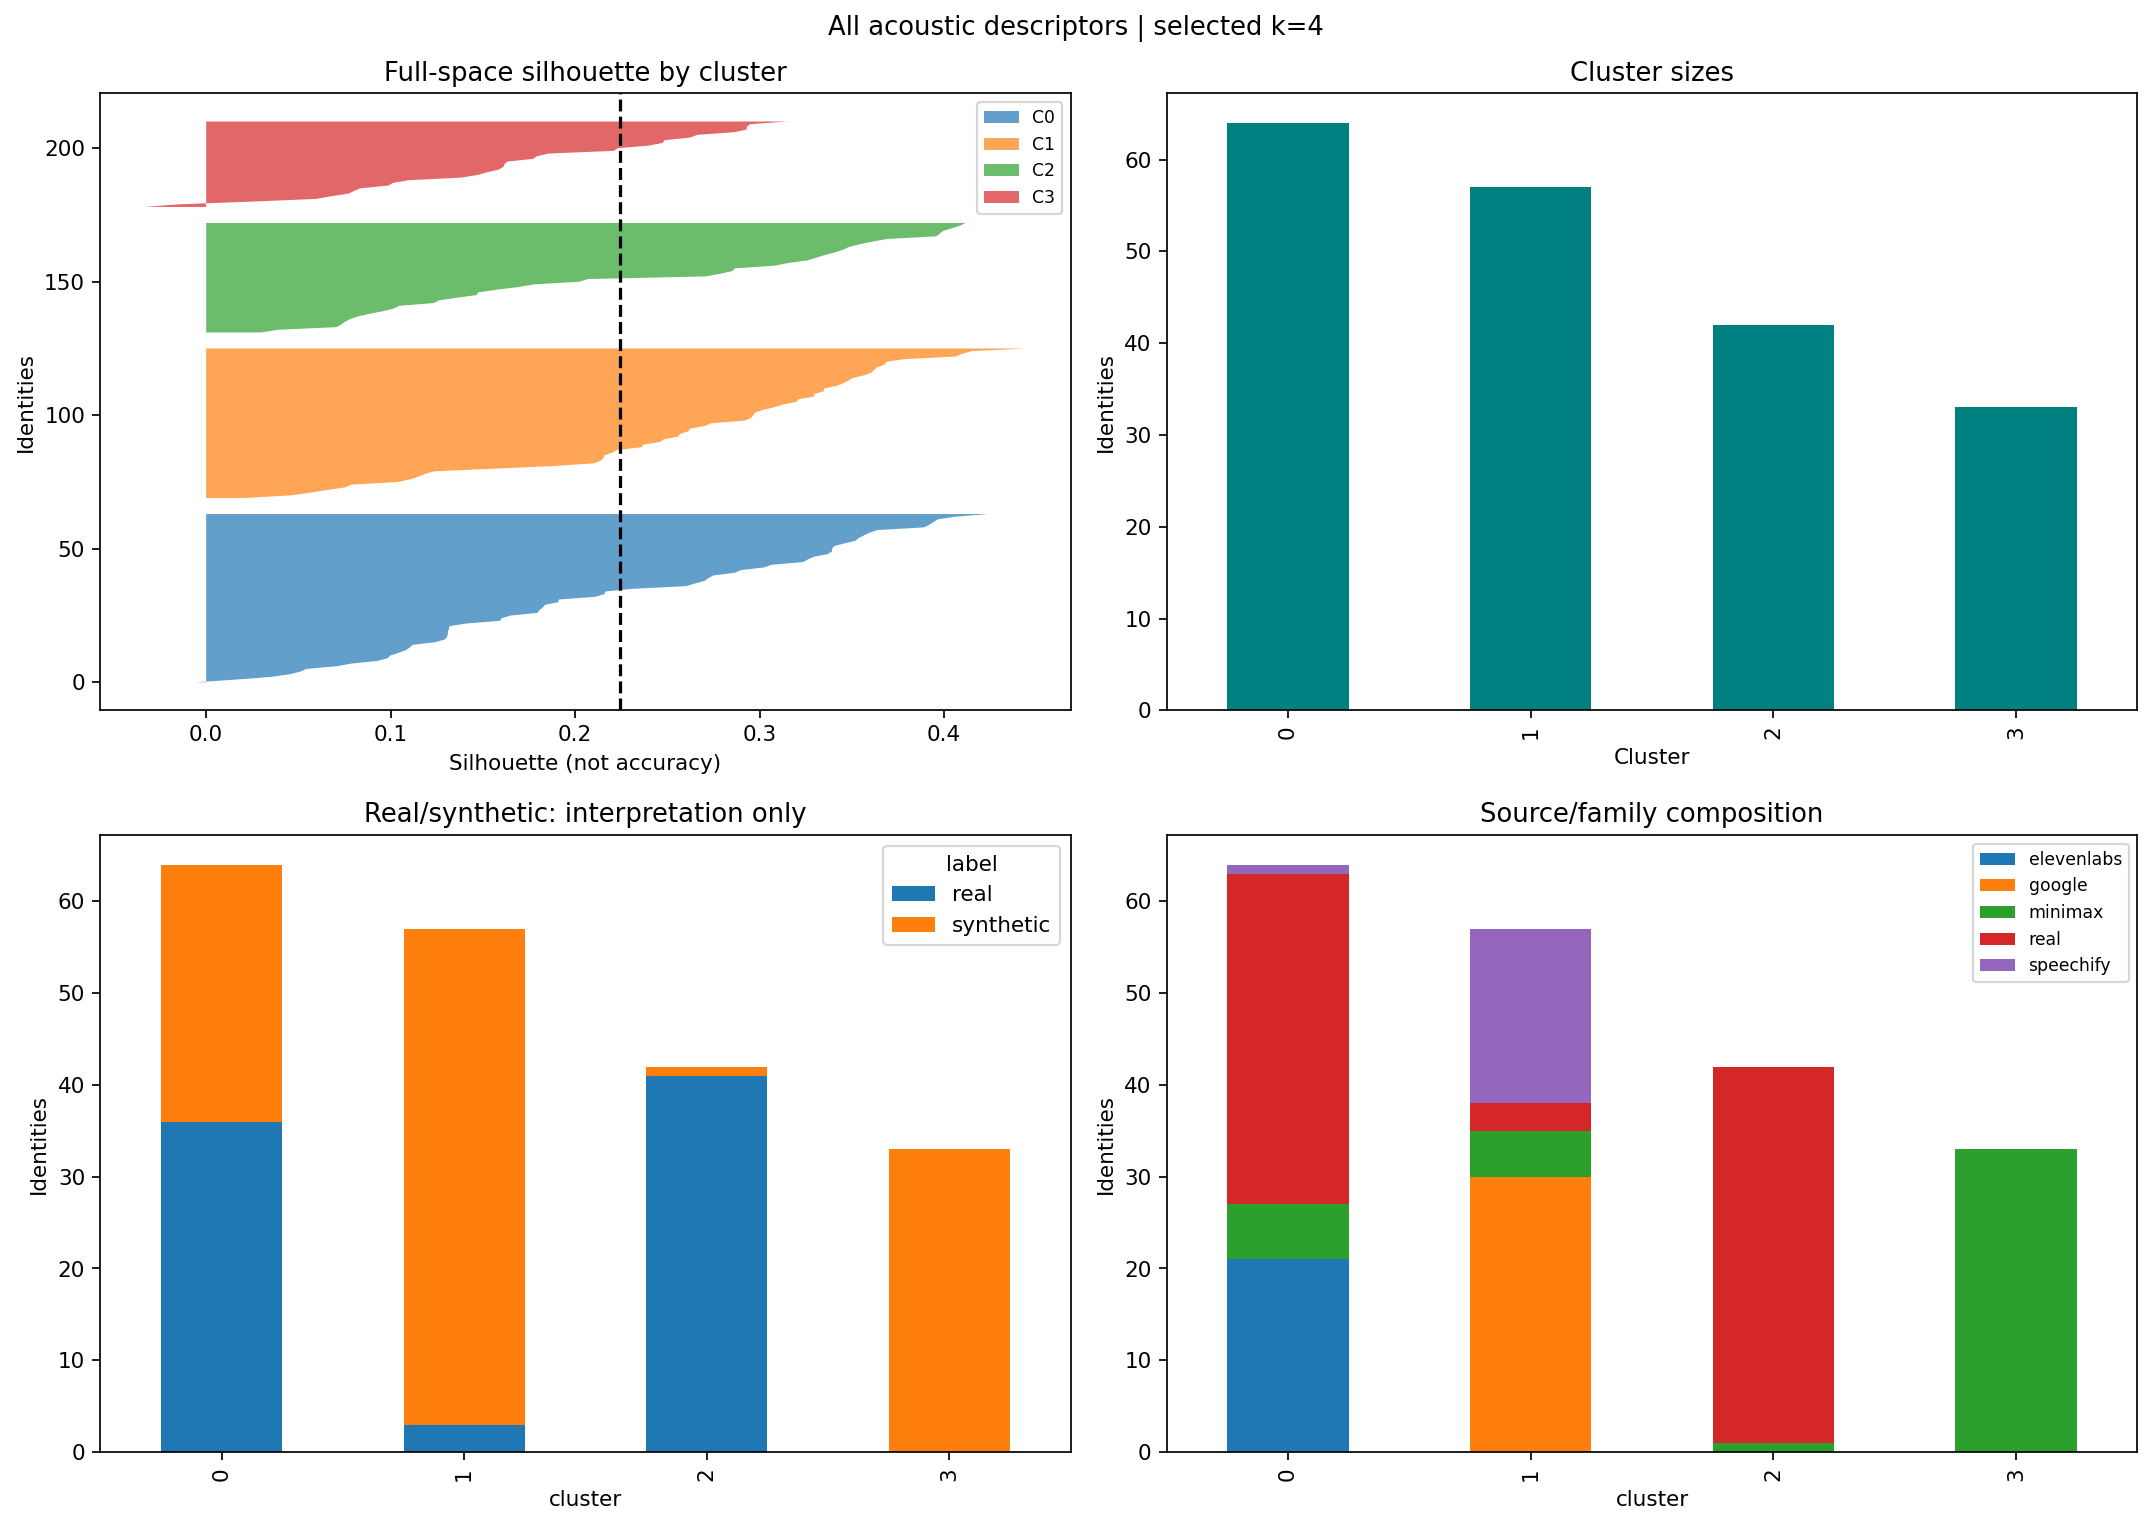

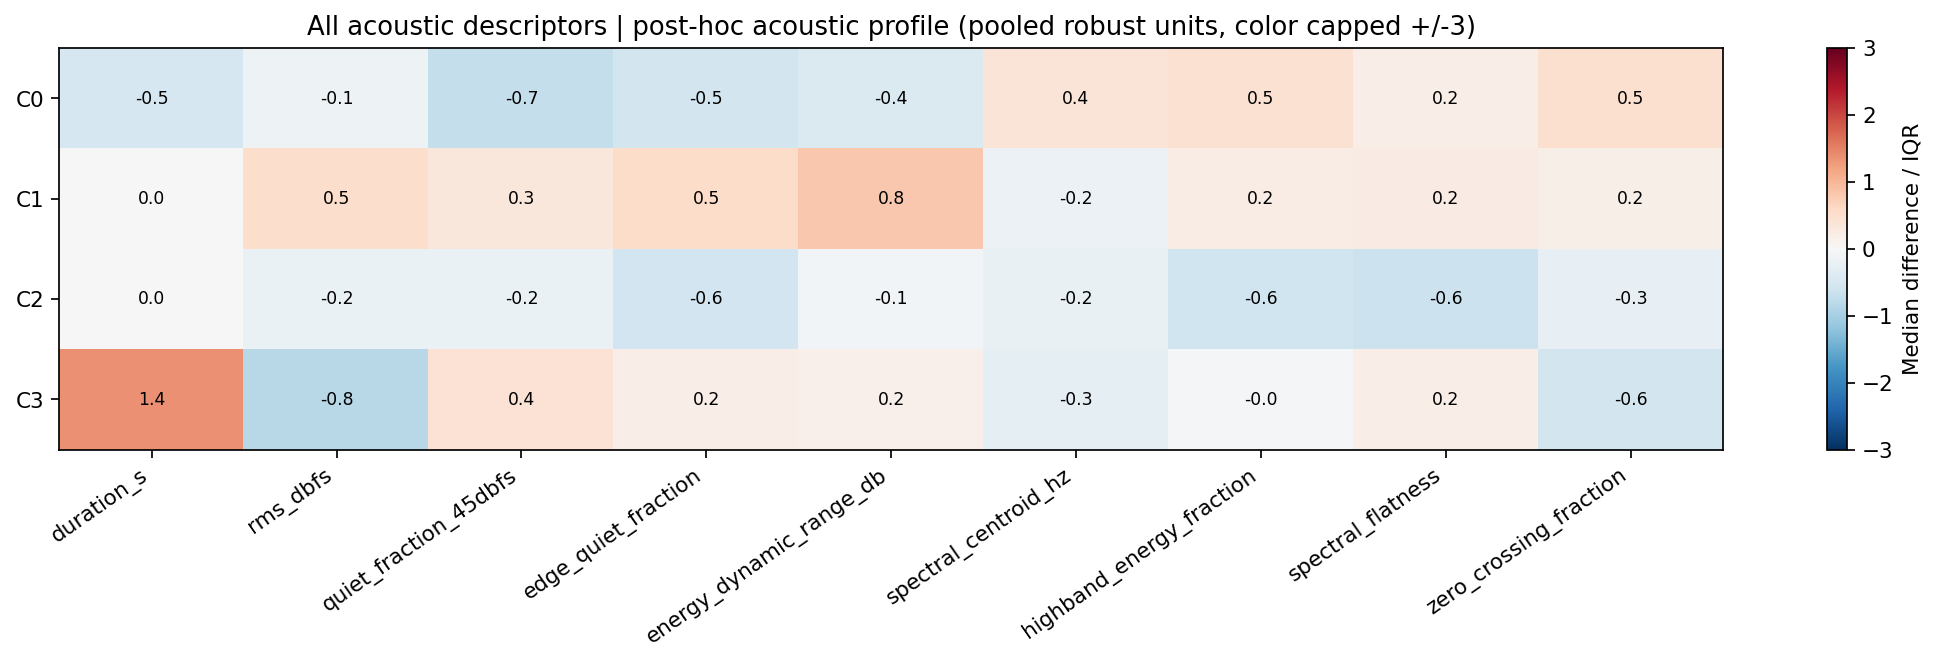

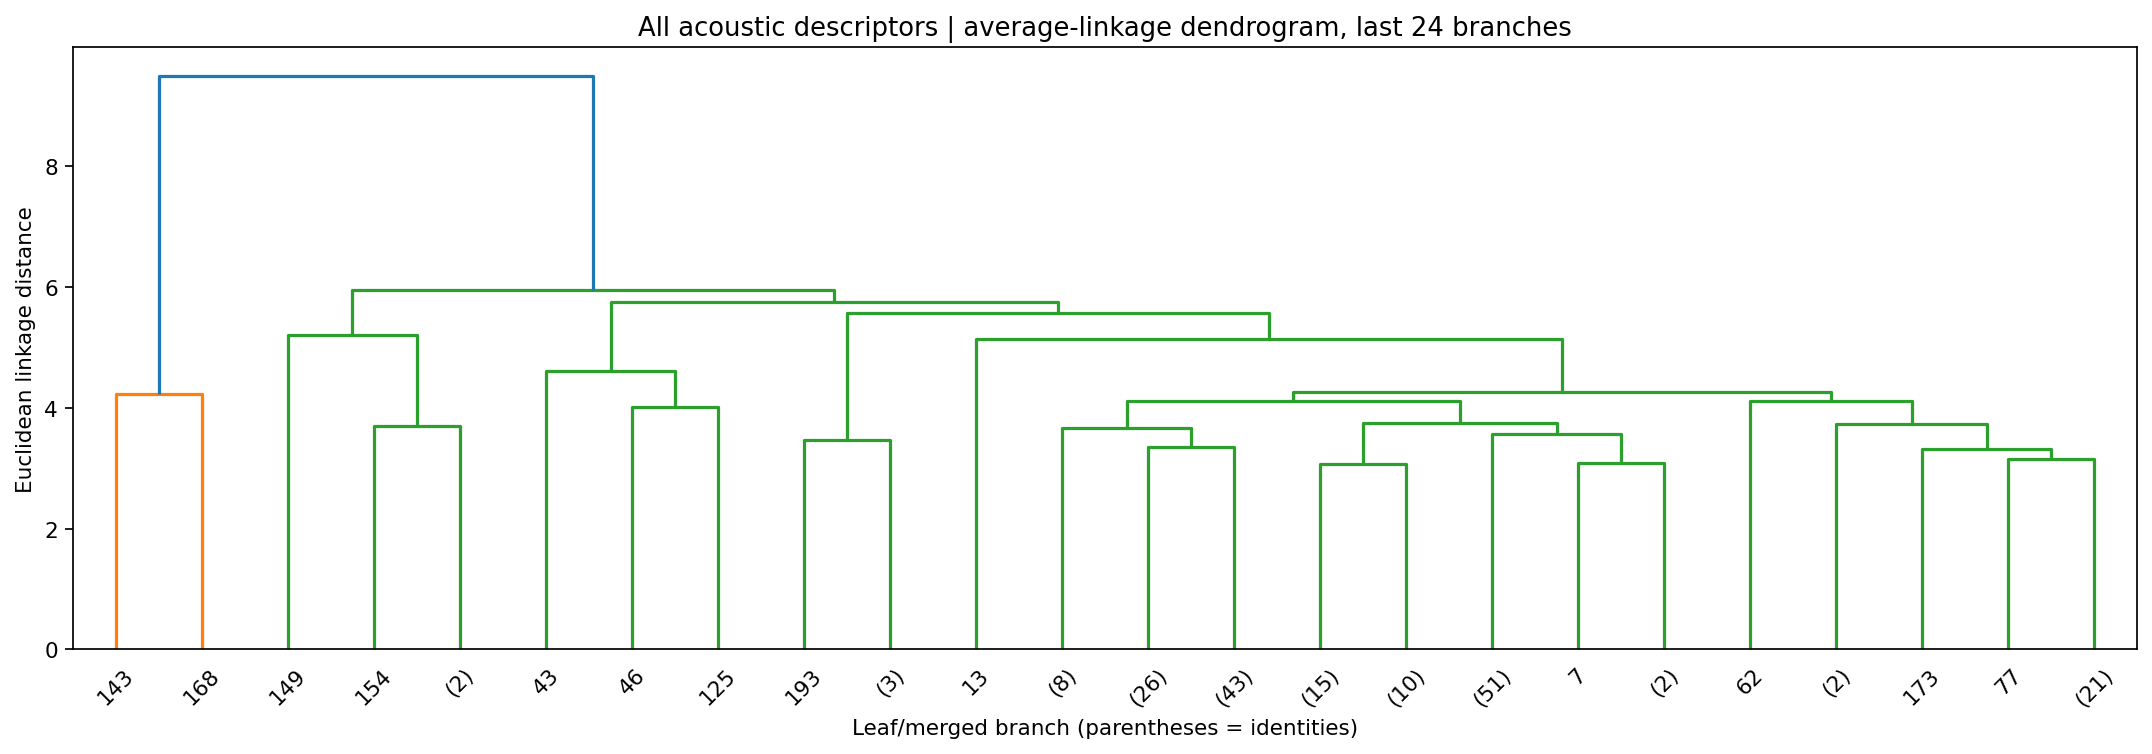

In [7]:
for name in ['acoustic_all16_original_maps','acoustic_all16_cluster_diagnostics','acoustic_all16_acoustic_cluster_profiles','acoustic_all16_hierarchy']:
    figure(name)


## 7. Alternative methods, stability and boundary sensitivity

Average-linkage is evaluated at the KMeans-selected k; it can isolate small branches. HDBSCAN uses fixed min_cluster_size=8 and min_samples=5, may leave points unassigned, and is not tuned to reveal class labels. Its noise label means **no density-cluster assignment**, not noisy/invalid audio. Silhouette on assigned density points must be read with coverage; high score on a small retained subset is not a fair full-sample comparison.

ARI measures agreement between partitions despite arbitrary numeric cluster labels: 1 is identical; near 0 means little agreement relative to chance, and negative is possible. Ten initializations and 20 random 80% identity subsamples quantify stability conditional on the fixed transform. They are not population confidence intervals.

Boundary comparisons report both independently selected k and the same original k. Acoustic changes include refitting the scaler for the trimmed view. Clip-level sensitivity fits on 515 clips at the same k and reports within-ID consistency; these clips remain dependent and do not replace the identity-balanced primary analysis.

,view,space,method,clusters,noise_fraction,assigned,silhouette_assigned,ari_vs_kmeans_on_assigned
0,original,acoustic_core,kmeans,3,0.000000,196,0.211788,1.000000
1,original,acoustic_core,average_linkage,3,0.000000,196,0.378161,0.011530
2,original,acoustic_core,hdbscan,2,0.734694,52,0.429796,0.923071
3,original,acoustic_all16,kmeans,4,0.000000,196,0.224279,1.000000
4,original,acoustic_all16,average_linkage,4,0.000000,196,0.273635,0.014628
5,original,acoustic_all16,hdbscan,2,0.260204,145,0.203085,0.253963
6,original,ecapa,kmeans,2,0.000000,196,0.057038,1.000000
7,original,ecapa,average_linkage,2,0.000000,196,0.038361,0.003400
8,original,ecapa,hdbscan,2,0.897959,20,0.227138,0.221226
9,original,hybrid,kmeans,3,0.000000,196,0.107954,1.000000


min  max  sum
view         space          method                        
edge_trimmed acoustic_all16 average_linkage    2  194  196
                            hdbscan           14  135  149
                            kmeans            43  153  196
             acoustic_core  average_linkage    3  193  196
                            hdbscan            8  116  124
                            kmeans            40  156  196
             ecapa          average_linkage    1  195  196
                            hdbscan            9   13   22
                            kmeans            82  114  196
             hybrid         average_linkage    3  193  196
                            kmeans            39  157  196
original     acoustic_all16 average_linkage    2  187  196
                            hdbscan           56   89  145
                            kmeans            33   64  196
             acoustic_core  average_linkage    2  191  196
                            hdbscan           21   31   52
                            kmeans            51   79  196
             ecapa          average_linkage    1  195  196
                            hdbscan            9   11   20
                            kmeans            84  112  196
             hybrid         average_linkage    2  190  196
                            kmeans            43   80  196

median  \
view         space          kind                                        
edge_trimmed acoustic_all16 80pct_subsample_fixed_transform  1.000000   
                            initialization                   1.000000   
             acoustic_core  80pct_subsample_fixed_transform  0.971952   
                            initialization                   0.976909   
             ecapa          80pct_subsample_fixed_transform  0.949366   
                            initialization                   0.979584   
             hybrid         80pct_subsample_fixed_transform  0.970414   
                            initialization                   1.000000   
original     acoustic_all16 80pct_subsample_fixed_transform  0.926028   
                            initialization                   0.986717   
             acoustic_core  80pct_subsample_fixed_transform  0.814865   
                            initialization                   1.000000   
             ecapa          80pct_subsample_fixed_transform  0.974519   
                            initialization                   1.000000   
             hybrid         80pct_subsample_fixed_transform  0.750712   
                            initialization                   0.918097   

                                                                  min  \
view         space          kind                                        
edge_trimmed acoustic_all16 80pct_subsample_fixed_transform  1.000000   
                            initialization                   1.000000   
             acoustic_core  80pct_subsample_fixed_transform  0.905176   
                            initialization                   0.976909   
             ecapa          80pct_subsample_fixed_transform  0.900039   
                            initialization                   0.979584   
             hybrid         80pct_subsample_fixed_transform  0.861395   
                            initialization                   0.976687   
original     acoustic_all16 80pct_subsample_fixed_transform  0.786678   
                            initialization                   0.986717   
             acoustic_core  80pct_subsample_fixed_transform  0.651652   
                            initialization                   0.984948   
             ecapa          80pct_subsample_fixed_transform  0.875868   
                            initialization                   0.979586   
             hybrid         80pct_subsample_fixed_transform  0.351197   
                            initialization                   0.772894   

                                                                  max  
view         space          kind                                       
edge_trimmed acoustic_all16 80pct_subsample_fixed_transform  1.000000  
                            initialization                   1.000000  
             acoustic_core  80pct_subsample_fixed_transform  1.000000  
                            initialization                   1.000000  
             ecapa          80pct_subsample_fixed_transform  1.000000  
                            initialization                   0.979584  
             hybrid         80pct_subsample_fixed_transform  1.000000  
                            initialization                   1.000000  
original     acoustic_all16 80pct_subsample_fixed_transform  1.000000  
                            initialization                   1.000000  
             acoustic_core  80pct_subsample_fixed_transform  1.000000  
                            initialization                   1.000000  
             ecapa          80pct_subsample_fixed_transform  1.000000  
                            initialization                   1.000000  
             hybrid         80pct_subsample_fixed_transform  0.982805  
                            initialization                   0.985954

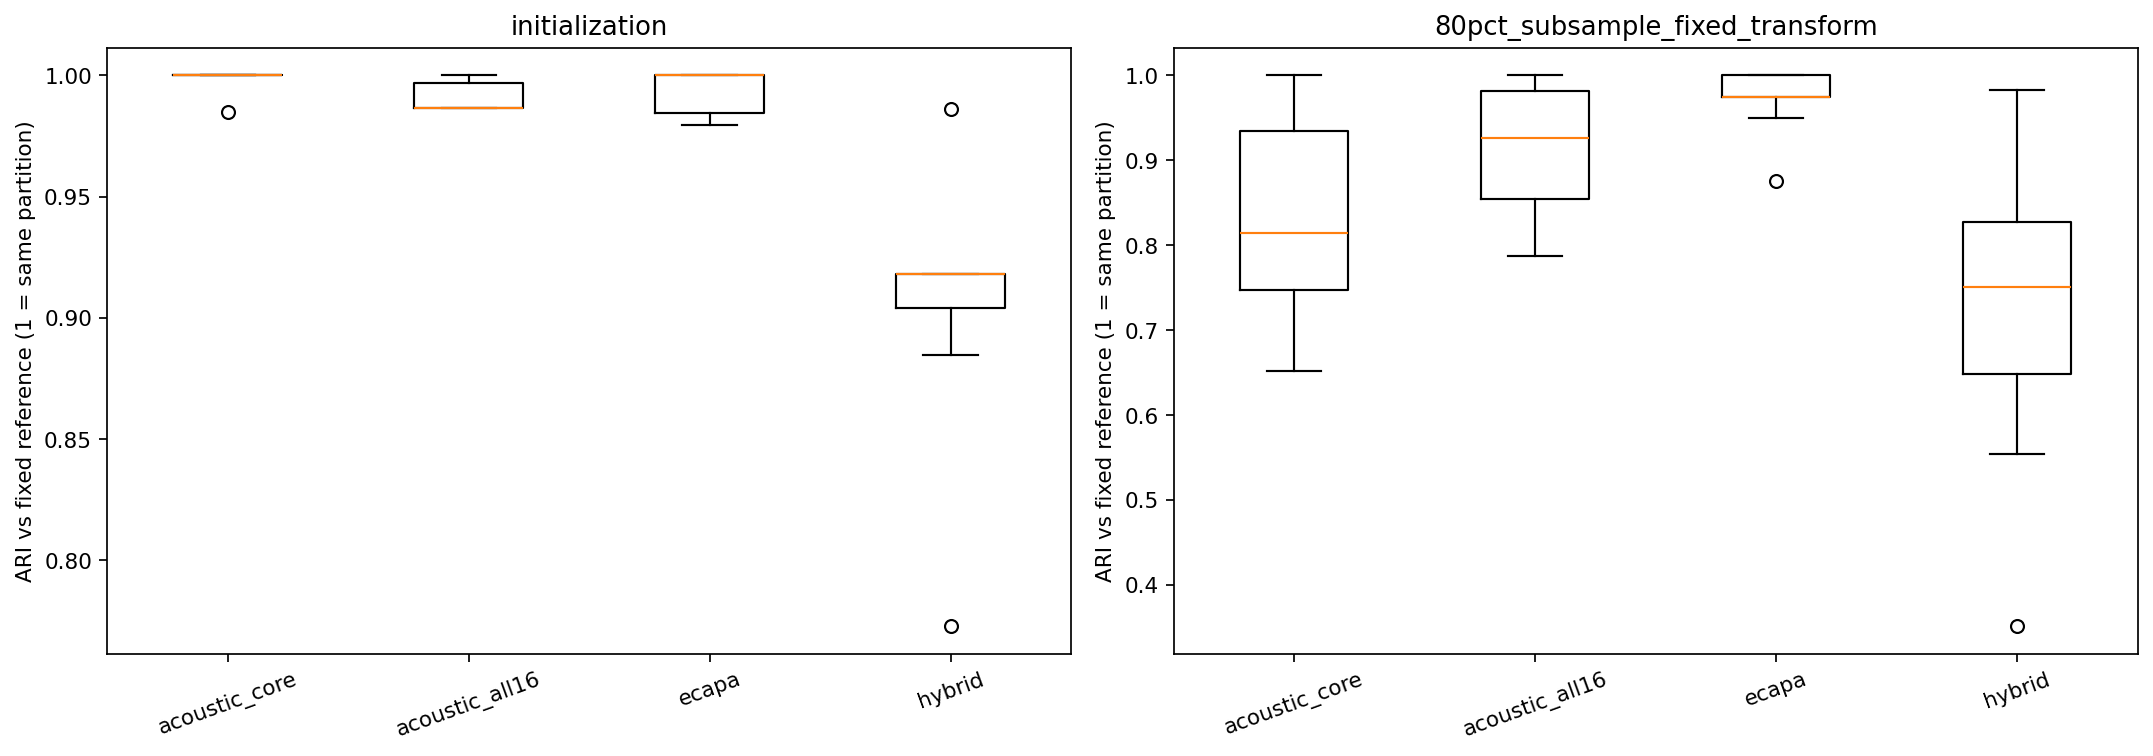

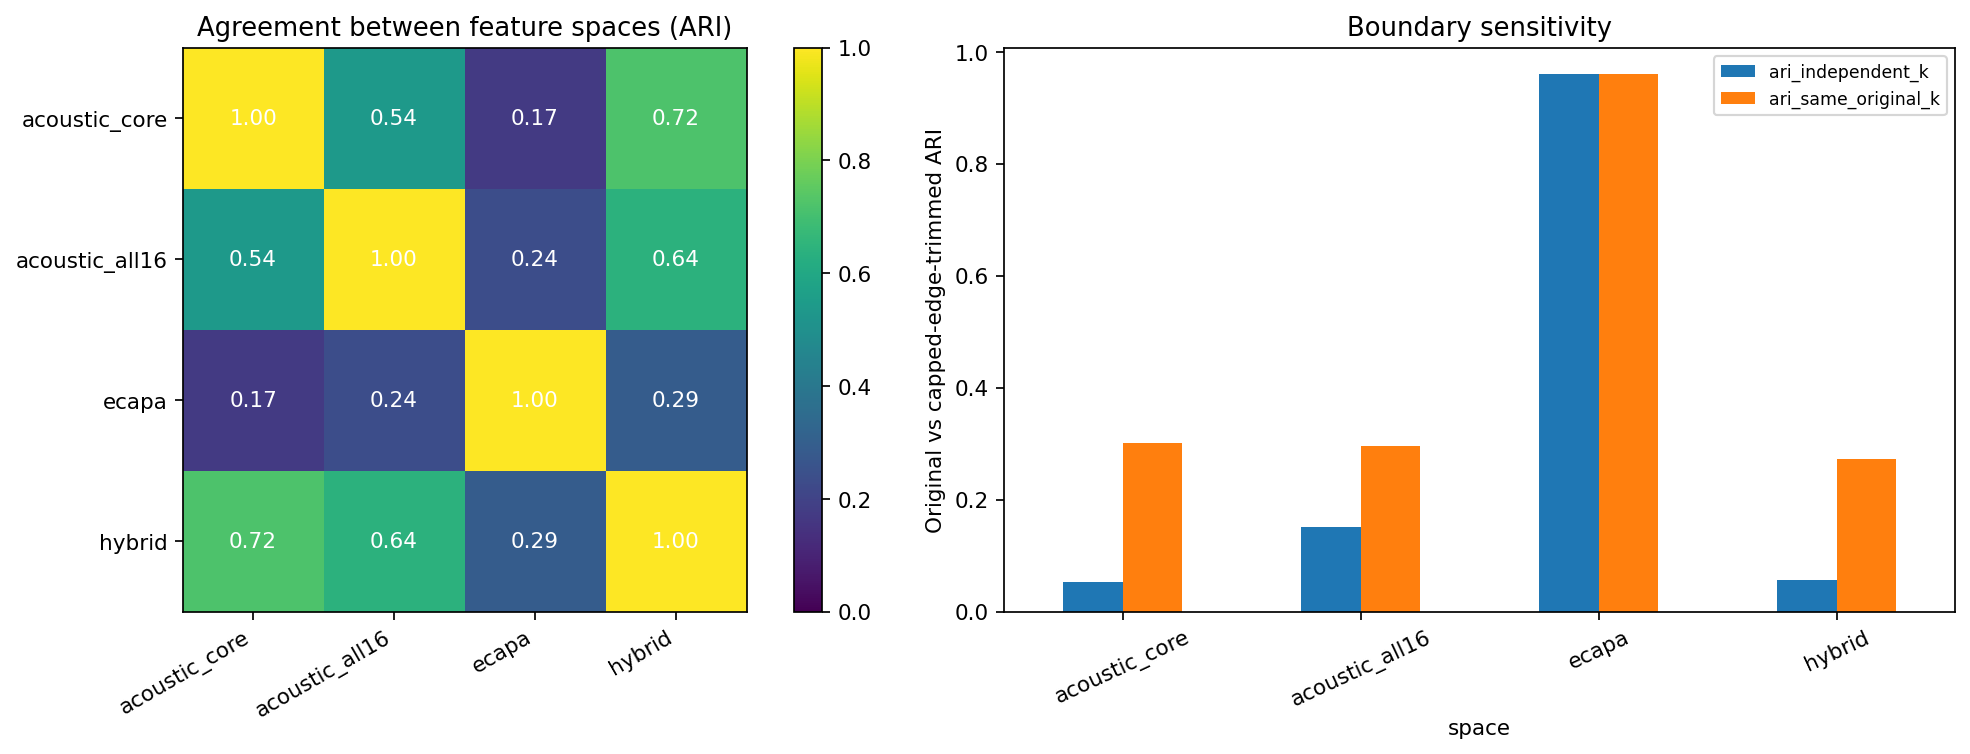

,space,original_k,trimmed_selected_k,ari_independent_k,ari_same_original_k
0,acoustic_core,3,2,0.053092,0.300485
1,acoustic_all16,4,2,0.151219,0.295697
2,ecapa,2,2,0.959379,0.959379
3,hybrid,3,2,0.055718,0.272490


identities  median_majority  split_identities
space          label                                                   
acoustic_all16 real               76         1.000000                36
               synthetic          96         0.666667                61
acoustic_core  real               76         1.000000                32
               synthetic          96         1.000000                42
ecapa          real               76         1.000000                 3
               synthetic          96         1.000000                 4
hybrid         real               76         1.000000                31
               synthetic          96         1.000000                40

In [8]:
display(table('method_comparison'))
method=table('all_method_assignments')
sizes=method.loc[method.cluster.ge(0)].groupby(['view','space','method','cluster']).size().rename('identities').reset_index()
display(sizes.groupby(['view','space','method']).identities.agg(['min','max','sum']))
display(table('stability').groupby(['view','space','kind']).ari.agg(['median','min','max']))
figure('stability_overview')
figure('partition_agreement_and_boundaries')
display(table('boundary_sensitivity'))
display(table('within_identity_clip_consistency').query('clips > 1').groupby(['space','label']).agg(identities=('group_id','size'),median_majority=('majority_fraction','median'),split_identities=('distinct_clusters',lambda s:int(s.gt(1).sum()))))


## 8. Inspect clusters and decide next steps

Cluster numbers are arbitrary local identifiers: cluster 0 in one space is not cluster 0 in another. Representative/distant members are based on distance to the full-space KMeans mean; neither is automatically good/bad audio. Linked real clips are unverified extracted intervals, and synthetic clips remain without completed human verification. Listen before semantic labels or exclusions.

Use clusters to audit source conditions and sample coverage. Do not remove groups until real/fake overlap looks better, assign biological sex/age from clusters, or split train/test by cluster alone. Freeze speaker/voice/text partitions, build same-Hebrew-text pairs with symmetric channel/boundary preparation, then repeat these diagnostics.

Source documentation: [clustering overview](https://scikit-learn.org/stable/modules/clustering.html), [silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html), [RobustScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.RobustScaler.html). Runtime versions and parameters are saved in provenance. No detector or demographic estimator is trained.

In [9]:
display(table('cluster_representatives').query("view == 'original'").head(24))
display(table('cluster_representative_audio_links').query("view == 'original'").head(12))
display(table('posthoc_label_associations'))
display(json.loads((OUT/'provenance.json').read_text()))
assert len(assign)==196*4*2
assert len(table('clip_assignments_sensitivity'))==515*4
assert metrics['api_calls']==0
print('Completed clustering in four spaces and two boundary views. No source audio changes, API calls or human labels.')


,view,space,cluster,role,distance_to_kmeans_mean,label,group_id,family,clips,sex_label,age_proxy_bin
0,original,acoustic_core,0,representative,0.755138,synthetic,elevenlabs:matilda,elevenlabs,4,not_comparable,not_comparable
1,original,acoustic_core,0,representative,0.776598,synthetic,elevenlabs:callum,elevenlabs,4,not_comparable,not_comparable
2,original,acoustic_core,0,representative,0.850175,real,bb517b6b-5537-4e2e-bb44-b23af280d655,real,3,male,30-39
3,original,acoustic_core,0,distant_member,3.366534,real,9b24c9cf-1262-4c28-9570-d57c8dd34e1e,real,1,male,60-69
4,original,acoustic_core,0,distant_member,4.675163,real,a6d23969-9763-485b-bbfc-28a9c0ea78b0,real,3,female,40-49
5,original,acoustic_core,1,representative,0.698530,synthetic,google:Zephyr,google,3,not_comparable,not_comparable
6,original,acoustic_core,1,representative,0.830517,synthetic,minimax:English_AnimeCharacter,minimax,2,not_comparable,not_comparable
7,original,acoustic_core,1,representative,0.831180,synthetic,google:Pulcherrima,google,3,not_comparable,not_comparable
8,original,acoustic_core,1,distant_member,4.561570,synthetic,google:Schedar,google,3,not_comparable,not_comparable
9,original,acoustic_core,1,distant_member,7.299287,synthetic,minimax:English_Whispering_girl,minimax,2,not_comparable,not_comparable


,view,space,cluster,role,distance_to_kmeans_mean,label,group_id,family,clips,sex_label,age_proxy_bin,sample_id,audio_path,text,model
0,original,acoustic_core,0,representative,0.755138,synthetic,elevenlabs:matilda,elevenlabs,4,not_comparable,not_comparable,d998cf3468ed538d3dd9,C:\project_ML\HebrewDeepFake\synthetic_pilot\a...,היום ניפגש בשעה שלוש ליד תחנת הרכבת בירושלים.,elevenlabs/eleven-v3
1,original,acoustic_core,0,representative,0.755138,synthetic,elevenlabs:matilda,elevenlabs,4,not_comparable,not_comparable,d41d4401fae2ccc60d74,C:\project_ML\HebrewDeepFake\synthetic_pilot\a...,היום ניפגש בשעה שלוש ליד תחנת הרכבת בירושלים.,elevenlabs/eleven-v3-conversational
2,original,acoustic_core,0,representative,0.755138,synthetic,elevenlabs:matilda,elevenlabs,4,not_comparable,not_comparable,0f9a0ce821cb737d5002,C:\project_ML\HebrewDeepFake\synthetic_pilot\a...,היום ניפגש בשעה שלוש ליד תחנת הרכבת בירושלים.,elevenlabs/eleven-v4
3,original,acoustic_core,0,representative,0.755138,synthetic,elevenlabs:matilda,elevenlabs,4,not_comparable,not_comparable,c369ce35a4fc8f081d50,C:\project_ML\HebrewDeepFake\synthetic_pilot\a...,היום ניפגש בשעה שלוש ליד תחנת הרכבת בירושלים.,elevenlabs/eleven-v4-turbo
4,original,acoustic_core,0,representative,0.776598,synthetic,elevenlabs:callum,elevenlabs,4,not_comparable,not_comparable,1912b392b0a189ba91e1,C:\project_ML\HebrewDeepFake\synthetic_pilot\a...,היום ניפגש בשעה שלוש ליד תחנת הרכבת בירושלים.,elevenlabs/eleven-v3
5,original,acoustic_core,0,representative,0.776598,synthetic,elevenlabs:callum,elevenlabs,4,not_comparable,not_comparable,648ca99e368790661f3b,C:\project_ML\HebrewDeepFake\synthetic_pilot\a...,היום ניפגש בשעה שלוש ליד תחנת הרכבת בירושלים.,elevenlabs/eleven-v3-conversational
6,original,acoustic_core,0,representative,0.776598,synthetic,elevenlabs:callum,elevenlabs,4,not_comparable,not_comparable,cf62f816e7b9a55147ca,C:\project_ML\HebrewDeepFake\synthetic_pilot\a...,היום ניפגש בשעה שלוש ליד תחנת הרכבת בירושלים.,elevenlabs/eleven-v4
7,original,acoustic_core,0,representative,0.776598,synthetic,elevenlabs:callum,elevenlabs,4,not_comparable,not_comparable,644b4af2c20ec265e2ef,C:\project_ML\HebrewDeepFake\synthetic_pilot\a...,היום ניפגש בשעה שלוש ליד תחנת הרכבת בירושלים.,elevenlabs/eleven-v4-turbo
8,original,acoustic_core,0,representative,0.850175,real,bb517b6b-5537-4e2e-bb44-b23af280d655,real,3,male,30-39,real_fQhaARKiYiP1bHpS0V957_15,C:\project_ML\HebrewDeepFake\voice_distributio...,תחושת עוררות רבה וחוסר מנוחה או האטה בפעילות ...,real
9,original,acoustic_core,0,representative,0.850175,real,bb517b6b-5537-4e2e-bb44-b23af280d655,real,3,male,30-39,real_hNNEwE5w1hlNoTMTgJsIP_8,C:\project_ML\HebrewDeepFake\voice_distributio...,אסטרוגן ממשיך להביא לגדילה של רירית הרחם והתע...,real


,view,space,field,nmi,interpretation
0,edge_trimmed,acoustic_all16,label,0.132423,posthoc association not accuracy; labels not u...
1,edge_trimmed,acoustic_all16,family,0.282884,posthoc association not accuracy; labels not u...
2,edge_trimmed,acoustic_core,label,0.118755,posthoc association not accuracy; labels not u...
3,edge_trimmed,acoustic_core,family,0.277268,posthoc association not accuracy; labels not u...
4,edge_trimmed,ecapa,label,0.857385,posthoc association not accuracy; labels not u...
5,edge_trimmed,ecapa,family,0.556364,posthoc association not accuracy; labels not u...
6,edge_trimmed,hybrid,label,0.137386,posthoc association not accuracy; labels not u...
7,edge_trimmed,hybrid,family,0.288995,posthoc association not accuracy; labels not u...
8,original,acoustic_all16,label,0.362731,posthoc association not accuracy; labels not u...
9,original,acoustic_all16,family,0.573728,posthoc association not accuracy; labels not u...


{'seed': 20261117,
 'runtime_versions': {'numpy': '1.26.4',
  'pandas': '2.2.3',
  'scipy': '1.15.3',
  'scikit-learn': '1.6.1',
  'matplotlib': '3.10.9'},
 'input_hashes': {'voice_distribution\\samples.csv': 'f021cee8334dc01c63c9755ac0a22f7903386710ecfebf408acce2b47e6c6d3e',
  'voice_distribution\\sample_acoustic_features.csv': 'bcedfe48f0bf49016df511f870d3210496420039a19f56aca8b269f584f90c45',
  'voice_distribution\\embeddings.npz': 'a6f945e9c3b2e850fbfce704b4a94a1196d31450a66133d06e6f0dba9b4bee5e',
  'voice_distribution\\centroids_original.npz': 'c4df25bf53c185f285094b2f8ca738d7b90a597248f23e26a411e24cb972f8a3',
  'voice_distribution\\centroids_edge_trimmed.npz': 'd0bc0f4a11fe7dee38c15c5776bb763b29ffbe9b0855b3b64ee1faf9e034b460',
  'cluster_voice_features.py': 'fe43789b238781810f041e164b5c84a8c45c981d0aa21a5ca11c0ed18e3ef20b',
  'CLUSTERING_PLAN.md': '99385d7d746b6c2cd2120fd3cfc40b1ba5b7b2dff897179dd3ac378857893f04'},
 'primary_unit': 'one nominal identity representative',
 'identit

Completed clustering in four spaces and two boundary views. No source audio changes, API calls or human labels.
